# SHL Hiring Assessment 2026
## Spoken Grammar Scoring Engine

### Objective

The objective is to predict a continuous grammar score for spoken audio recordings.

The training dataset contains 769 labelled recordings and the evaluation dataset contains 216 recordings. The target represents the quality of grammatical structure and syntax in spoken responses.

### Evaluation

The competition evaluates predictions using **Pearson Correlation** and **RMSE**.

This notebook documents the complete data inspection, audio feature engineering, model development, validation, ensemble, calibration and final prediction pipeline.

### Reproducibility and Data Access

The competition dataset is not included in this repository. Run the notebook in Kaggle after attaching the authorized SHL Hiring Assessment 2026 competition dataset. The notebook uses the Kaggle dataset path shown in the setup cells and requires Internet access and a CUDA GPU for the Faster-Whisper transcription step. Record-level output tables and the example transcript are omitted from this public copy; aggregate experiment results are retained.



In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

## 1. Dataset and Environment Setup

The competition data is loaded directly from the Kaggle competition input directory.

The dataset includes:

- `train.csv` — training filenames and grammar labels
- `test.csv` — evaluation filenames and placeholder labels
- `sample_submission.csv` — example submission file
- WAV audio files for the training and evaluation sets


In [ ]:
import os
from pathlib import Path

# Find all CSV files available in Kaggle input
csv_files = list(Path("/kaggle/input").rglob("*.csv"))

print("CSV files found:")
for f in csv_files:
    print(f)

print("\nInput directories:")
for p in Path("/kaggle/input").iterdir():
    print(p)

## 2. Dataset Inspection and Integrity Checks

Before modelling, the dataset structure is inspected for sample counts, column structure, missing values, label distribution, audio availability and possible train/test leakage.

Because some filenames occur in both train and test CSV files, the actual audio contents are compared to verify that the recordings themselves are different.


In [ ]:
import pandas as pd
import hashlib
from pathlib import Path

# --------------------------------------------------
# Automatically locate the CSV files
# --------------------------------------------------

csv_files = list(Path("/kaggle/input").rglob("*.csv"))

train_path = next(
    p for p in csv_files
    if p.name.lower() == "train.csv"
)

test_path = next(
    p for p in csv_files
    if p.name.lower() == "test.csv"
)

sample_path = next(
    p for p in csv_files
    if p.name.lower() == "sample_submission.csv"
)

print("TRAIN :", train_path)
print("TEST  :", test_path)
print("SAMPLE:", sample_path)

train = pd.read_csv(train_path)
test = pd.read_csv(test_path)
sample = pd.read_csv(sample_path)

print("\nShapes")
print("Train :", train.shape)
print("Test  :", test.shape)
print("Sample:", sample.shape)

print("\nTrain columns:", train.columns.tolist())
print("Test columns :", test.columns.tolist())
print("Sample columns:", sample.columns.tolist())


# --------------------------------------------------
# Find the audio directories
# --------------------------------------------------

root = Path("/kaggle/input")

wav_files = list(root.rglob("*.wav"))

print("\nTotal WAV files found:", len(wav_files))

# Build filename -> path mapping
wav_map = {}

for p in wav_files:
    wav_map.setdefault(p.name, []).append(p)

train_names = set(train["filename"])
test_names = set(test["filename"])

overlap = sorted(train_names & test_names)

print("\nTrain filenames:", len(train_names))
print("Test filenames :", len(test_names))
print("Filename overlap:", len(overlap))

print("\nFirst 20 overlapping names:")
print(overlap[:20])


# --------------------------------------------------
# Compare actual audio files
# --------------------------------------------------

def md5_file(path, chunk_size=1024 * 1024):
    h = hashlib.md5()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)

            if not chunk:
                break

            h.update(chunk)

    return h.hexdigest()


same_audio = []
different_audio = []
missing_paths = []

for name in overlap:

    paths = wav_map.get(name, [])

    # We expect separate train/test copies
    if len(paths) < 2:
        missing_paths.append((name, paths))
        continue

    hashes = {}

    for p in paths:
        hashes[str(p)] = md5_file(p)

    unique_hashes = set(hashes.values())

    if len(unique_hashes) == 1:
        same_audio.append((name, list(hashes.keys())))
    else:
        different_audio.append((name, hashes))


print("\n==============================")
print("AUDIO DUPLICATION CHECK")
print("==============================")

print("Same audio content :", len(same_audio))
print("Different audio    :", len(different_audio))
print("Missing/ambiguous  :", len(missing_paths))

print("\nSame audio examples:")
for x in same_audio[:5]:
    print(x)

print("\nDifferent audio examples:")
for x in different_audio[:5]:
    print(x)

### 2.1 Train/Test Audio Verification


In [ ]:
import pandas as pd
import hashlib
from pathlib import Path

# -------------------------------------------------------
# Locate files
# -------------------------------------------------------

BASE = Path("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final")
TRAIN_DIR = BASE / "train"
TEST_DIR = BASE / "test"

train = pd.read_csv(BASE / "train.csv")
test = pd.read_csv(BASE / "test.csv")
sample = pd.read_csv(BASE / "sample_submission.csv")

# -------------------------------------------------------
# 1. Inspect CSV contents
# -------------------------------------------------------

print("=" * 60)
print("TRAIN")
print("=" * 60)

print(train.head(10))
print("\nTrain dtypes:")
print(train.dtypes)
print("\nTrain missing values:")
print(train.isna().sum())

print("\n" + "=" * 60)
print("TEST")
print("=" * 60)

print(test.head(10))
print("\nTest dtypes:")
print(test.dtypes)
print("\nTest missing values:")
print(test.isna().sum())

print("\nUnique test labels:")
print(test["label"].unique()[:30])

print("\nNumber of unique test labels:")
print(test["label"].nunique(dropna=True))

print("\n" + "=" * 60)
print("SAMPLE SUBMISSION")
print("=" * 60)

print(sample.head(10))
print("\nSample shape:", sample.shape)
print("Sample missing values:")
print(sample.isna().sum())

# -------------------------------------------------------
# 2. Verify actual train/test audio files
# -------------------------------------------------------

print("\n" + "=" * 60)
print("AUDIO FILE COUNTS")
print("=" * 60)

train_wavs = sorted(TRAIN_DIR.glob("*.wav"))
test_wavs = sorted(TEST_DIR.glob("*.wav"))

print("Train WAV files:", len(train_wavs))
print("Test WAV files :", len(test_wavs))

# -------------------------------------------------------
# 3. Compare overlapping filenames
# -------------------------------------------------------

def md5_file(path, chunk_size=1024 * 1024):
    h = hashlib.md5()

    with open(path, "rb") as f:
        while True:
            chunk = f.read(chunk_size)
            if not chunk:
                break
            h.update(chunk)

    return h.hexdigest()


train_names = set(train["filename"])
test_names = set(test["filename"])
overlap = sorted(train_names & test_names)

same_audio = []
different_audio = []

for name in overlap:
    train_path = TRAIN_DIR / name
    test_path = TEST_DIR / name

    if not train_path.exists() or not test_path.exists():
        continue

    h_train = md5_file(train_path)
    h_test = md5_file(test_path)

    if h_train == h_test:
        same_audio.append(name)
    else:
        different_audio.append(name)

print("\n" + "=" * 60)
print("TRAIN / TEST OVERLAP CHECK")
print("=" * 60)

print("Overlapping filenames :", len(overlap))
print("Same actual audio     :", len(same_audio))
print("Different actual audio:", len(different_audio))

print("\nSame-audio examples:")
print(same_audio[:20])

print("\nDifferent-audio examples:")
print(different_audio[:20])

# -------------------------------------------------------
# 4. Check filename differences
# -------------------------------------------------------

train_only = sorted(train_names - test_names)
test_only = sorted(test_names - train_names)

print("\n" + "=" * 60)
print("FILENAME SETS")
print("=" * 60)

print("Train-only files:", len(train_only))
print("Test-only files :", len(test_only))

print("\nTest-only filenames:")
print(test_only)

# -------------------------------------------------------
# 5. Compare sample submission IDs with test IDs
# -------------------------------------------------------

sample_names = set(sample["filename"])

print("\n" + "=" * 60)
print("SAMPLE SUBMISSION CHECK")
print("=" * 60)

print("Test filenames:", len(test_names))
print("Sample filenames:", len(sample_names))

print("Overlap:", len(test_names & sample_names))
print("Sample-only:", len(sample_names - test_names))
print("Test-only:", len(test_names - sample_names))

print("\nSample-only examples:")
print(sorted(sample_names - test_names)[:20])

print("\nTest-only examples:")
print(sorted(test_names - sample_names)[:20])

## 3. Baseline Audio Feature Extraction

A lightweight acoustic baseline is created using basic signal-level characteristics:

- Audio duration
- RMS energy
- Zero-crossing rate
- Speech activity ratio
- Sampling rate

These inexpensive features provide an initial estimate of the predictive signal present in the recordings.


In [ ]:
import os
import numpy as np
import pandas as pd
import librosa
from pathlib import Path
from tqdm.auto import tqdm

BASE = Path("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final")

TRAIN_DIR = BASE / "train"
TEST_DIR = BASE / "test"

train = pd.read_csv(BASE / "train.csv")
test = pd.read_csv(BASE / "test.csv")

# ---------------------------------------------------------
# Audio metadata extraction
# ---------------------------------------------------------

def get_audio_metadata(path):
    try:
        y, sr = librosa.load(path, sr=None, mono=True)

        duration = len(y) / sr

        # Basic signal statistics
        rms = float(np.sqrt(np.mean(y ** 2)))
        zcr = float(np.mean(librosa.feature.zero_crossing_rate(y)))

        # Silence / low-energy estimate
        threshold = max(0.005, 0.1 * np.max(np.abs(y)))
        active_ratio = float(np.mean(np.abs(y) > threshold))

        return {
            "sample_rate": sr,
            "duration": duration,
            "rms": rms,
            "zcr": zcr,
            "active_ratio": active_ratio,
        }

    except Exception as e:
        return {
            "sample_rate": np.nan,
            "duration": np.nan,
            "rms": np.nan,
            "zcr": np.nan,
            "active_ratio": np.nan,
        }


# ---------------------------------------------------------
# Process TRAIN
# ---------------------------------------------------------

train_rows = []

for filename in tqdm(train["filename"], desc="Processing train"):
    path = TRAIN_DIR / filename

    meta = get_audio_metadata(path)
    meta["filename"] = filename

    train_rows.append(meta)


train_meta = pd.DataFrame(train_rows)

train_meta = train_meta.merge(
    train,
    on="filename",
    how="left"
)


# ---------------------------------------------------------
# Process TEST
# ---------------------------------------------------------

test_rows = []

for filename in tqdm(test["filename"], desc="Processing test"):
    path = TEST_DIR / filename

    meta = get_audio_metadata(path)
    meta["filename"] = filename

    test_rows.append(meta)


test_meta = pd.DataFrame(test_rows)


# ---------------------------------------------------------
# Display results
# ---------------------------------------------------------

print("\nTRAIN METADATA")
display(train_meta.head())

print("\nTEST METADATA")
display(test_meta.head())

print("\nTRAIN SHAPE:", train_meta.shape)
print("TEST SHAPE :", test_meta.shape)

print("\nTRAIN SUMMARY")
display(train_meta.describe(include="all"))

print("\nMissing values")
display(train_meta.isna().sum())

# Save so we don't need to recompute it
train_meta.to_csv("/kaggle/working/train_audio_metadata.csv", index=False)
test_meta.to_csv("/kaggle/working/test_audio_metadata.csv", index=False)

print("\nSaved:")
print("/kaggle/working/train_audio_metadata.csv")
print("/kaggle/working/test_audio_metadata.csv")

### 3.1 Robust Baseline Feature Extraction

The baseline metadata extraction is repeated with explicit error tracking and the resulting feature tables are cached for reuse.


In [ ]:
import numpy as np
import pandas as pd
import librosa
from pathlib import Path
from tqdm.auto import tqdm

BASE = Path("/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final")

TRAIN_DIR = BASE / "train"
TEST_DIR = BASE / "test"

train = pd.read_csv(BASE / "train.csv")
test = pd.read_csv(BASE / "test.csv")

errors = []

def get_audio_metadata(path):
    try:
        y, sr = librosa.load(path, sr=None, mono=True)

        duration = len(y) / sr

        rms = float(np.sqrt(np.mean(y ** 2)))
        zcr = float(np.mean(
            librosa.feature.zero_crossing_rate(y)
        ))

        # Approximate proportion of active/non-silent samples
        peak = np.max(np.abs(y))

        if peak > 0:
            threshold = max(0.005, 0.1 * peak)
            active_ratio = float(
                np.mean(np.abs(y) > threshold)
            )
        else:
            active_ratio = 0.0

        return {
            "sample_rate": sr,
            "duration": duration,
            "rms": rms,
            "zcr": zcr,
            "active_ratio": active_ratio,
        }

    except Exception as e:
        errors.append((str(path), str(e)))

        return {
            "sample_rate": np.nan,
            "duration": np.nan,
            "rms": np.nan,
            "zcr": np.nan,
            "active_ratio": np.nan,
        }


# =========================
# TRAIN
# =========================

train_rows = []

for filename in tqdm(train["filename"], desc="Processing train"):
    meta = get_audio_metadata(TRAIN_DIR / filename)
    meta["filename"] = filename
    train_rows.append(meta)

train_meta = pd.DataFrame(train_rows)

train_meta = train_meta.merge(
    train,
    on="filename",
    how="left"
)


# =========================
# TEST
# =========================

test_rows = []

for filename in tqdm(test["filename"], desc="Processing test"):
    meta = get_audio_metadata(TEST_DIR / filename)
    meta["filename"] = filename
    test_rows.append(meta)

test_meta = pd.DataFrame(test_rows)


# =========================
# RESULTS
# =========================

print("\nTRAIN SHAPE:", train_meta.shape)
print("TEST SHAPE :", test_meta.shape)

print("\nTRAIN SAMPLE")
display(train_meta.head())

print("\nTEST SAMPLE")
display(test_meta.head())

print("\nTRAIN SUMMARY")
display(train_meta.describe())

print("\nMISSING VALUES")
display(train_meta.isna().sum())

print("\nAUDIO PROCESSING ERRORS:", len(errors))

if errors:
    print("\nFirst errors:")
    for item in errors[:10]:
        print(item)

# Save features
train_meta.to_csv(
    "/kaggle/working/train_audio_metadata.csv",
    index=False
)

test_meta.to_csv(
    "/kaggle/working/test_audio_metadata.csv",
    index=False
)

print("\nSaved successfully.")

## 4. Baseline Feature Analysis

The baseline acoustic features are examined through their relationship with the grammar score and their distribution across the labelled samples.


In [18]:
df = train_meta.copy()

features = [
    "sample_rate",
    "duration",
    "rms",
    "zcr",
    "active_ratio"
]

print("Correlation with grammar score:")
display(
    df[features + ["label"]]
    .corr()["label"]
    .sort_values(ascending=False)
)

print("\nMean feature values by label:")
display(
    df.groupby("label")[features]
      .mean()
      .round(4)
)

print("\nLabel distribution:")
display(
    df["label"]
      .value_counts()
      .sort_index()
)

Correlation with grammar score:


label           1.000000
duration        0.087380
rms            -0.235030
zcr            -0.373713
active_ratio   -0.457185
sample_rate          NaN
Name: label, dtype: float64


Mean feature values by label:


,sample_rate,duration,rms,zcr,active_ratio
label,,,,,
0.0,16000.0,57.8642,0.1220,0.4546,0.4062
1.0,16000.0,45.0600,0.0310,0.1354,0.2564
1.5,16000.0,60.0698,0.0470,0.1276,0.0821
2.0,16000.0,53.5611,0.0510,0.1351,0.1327
2.5,16000.0,55.1259,0.0559,0.1338,0.1372
3.0,16000.0,55.7260,0.0596,0.1356,0.1399
3.5,16000.0,56.6489,0.0576,0.1462,0.1398
4.0,16000.0,52.8096,0.0575,0.1530,0.1322
4.5,16000.0,58.3918,0.0578,0.1625,0.1258



Label distribution:


label
0.0     37
1.0      1
1.5      3
2.0    102
2.5     79
3.0    174
3.5     64
4.0    124
4.5     52
5.0    133
Name: count, dtype: int64

## 5. Baseline Machine Learning Models

The initial acoustic representation is evaluated using both linear and nonlinear regression models.

Five-fold cross-validation with a fixed random seed is used to obtain comparable out-of-fold predictions.

Models evaluated:

- Ridge Regression
- ExtraTrees Regressor
- Random Forest Regressor


In [19]:
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import Ridge
from sklearn.ensemble import ExtraTreesRegressor, RandomForestRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

from scipy.stats import pearsonr


# =========================================================
# Data
# =========================================================

df = train_meta.copy()

features = [
    "duration",
    "rms",
    "zcr",
    "active_ratio"
]

X = df[features].copy()
y = df["label"].values


# =========================================================
# Validation
# =========================================================
# We deliberately use the same folds for every model.

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# =========================================================
# Evaluation function
# =========================================================

def evaluate_predictions(y_true, pred, name):
    pearson = pearsonr(y_true, pred)[0]
    rmse = np.sqrt(mean_squared_error(y_true, pred))
    mae = mean_absolute_error(y_true, pred)
    r2 = r2_score(y_true, pred)

    print(f"\n{name}")
    print("-" * 40)
    print(f"Pearson : {pearson:.4f}")
    print(f"RMSE    : {rmse:.4f}")
    print(f"MAE     : {mae:.4f}")
    print(f"R²      : {r2:.4f}")

    return {
        "model": name,
        "pearson": pearson,
        "rmse": rmse,
        "mae": mae,
        "r2": r2
    }


results = []


# =========================================================
# 1. Ridge Regression
# =========================================================

ridge = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    Ridge(alpha=10.0)
)

ridge_pred = cross_val_predict(
    ridge,
    X,
    y,
    cv=cv
)

results.append(
    evaluate_predictions(
        y,
        ridge_pred,
        "Ridge"
    )
)


# =========================================================
# 2. Extra Trees
# =========================================================

extra = make_pipeline(
    SimpleImputer(strategy="median"),
    ExtraTreesRegressor(
        n_estimators=500,
        min_samples_leaf=3,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )
)

extra_pred = cross_val_predict(
    extra,
    X,
    y,
    cv=cv,
    n_jobs=-1
)

results.append(
    evaluate_predictions(
        y,
        extra_pred,
        "ExtraTrees"
    )
)


# =========================================================
# 3. Random Forest
# =========================================================

rf = make_pipeline(
    SimpleImputer(strategy="median"),
    RandomForestRegressor(
        n_estimators=500,
        min_samples_leaf=4,
        max_features=1.0,
        random_state=42,
        n_jobs=-1
    )
)

rf_pred = cross_val_predict(
    rf,
    X,
    y,
    cv=cv,
    n_jobs=-1
)

results.append(
    evaluate_predictions(
        y,
        rf_pred,
        "RandomForest"
    )
)


# =========================================================
# Comparison
# =========================================================

results_df = pd.DataFrame(results)

print("\nMODEL COMPARISON")
display(
    results_df.sort_values(
        "pearson",
        ascending=False
    ).reset_index(drop=True)
)


Ridge
----------------------------------------
Pearson : 0.5024
RMSE    : 1.0706
MAE     : 0.9170
R²      : 0.2524

ExtraTrees
----------------------------------------
Pearson : 0.6735
RMSE    : 0.9152
MAE     : 0.7508
R²      : 0.4536

RandomForest
----------------------------------------
Pearson : 0.6827
RMSE    : 0.9055
MAE     : 0.7278
R²      : 0.4651

MODEL COMPARISON


,model,pearson,rmse,mae,r2
0,RandomForest,0.682699,0.905548,0.727796,0.465133
1,ExtraTrees,0.673527,0.915229,0.750841,0.453636
2,Ridge,0.502429,1.070574,0.916951,0.252422


## 6. Rich Acoustic Feature Engineering

To capture more information from spoken speech, a richer fixed-length acoustic representation is extracted.

The feature set includes:

- RMS energy statistics
- Zero-crossing statistics
- Spectral centroid
- Spectral bandwidth
- Spectral roll-off
- Spectral flatness
- Spectral contrast
- MFCCs
- First-order MFCC deltas
- Second-order MFCC deltas
- Pitch statistics
- Speech activity and silence ratios
- Duration and amplitude-related features

For time-varying features, summary statistics such as mean, standard deviation, minimum and maximum are used.


In [ ]:
import numpy as np
import pandas as pd
import librosa
from pathlib import Path
from tqdm.auto import tqdm

BASE = Path(
    "/kaggle/input/competitions/"
    "shl-hiring-assessment-2026/Dataset_Final"
)

TRAIN_DIR = BASE / "train"
TEST_DIR = BASE / "test"

train = pd.read_csv(BASE / "train.csv")
test = pd.read_csv(BASE / "test.csv")


# =========================================================
# Feature helper
# =========================================================

def summarize_feature(x, prefix):
    x = np.asarray(x, dtype=np.float32)

    return {
        f"{prefix}_mean": float(np.mean(x)),
        f"{prefix}_std": float(np.std(x)),
        f"{prefix}_min": float(np.min(x)),
        f"{prefix}_max": float(np.max(x)),
    }


def extract_audio_features(path):

    y, sr = librosa.load(
        path,
        sr=None,
        mono=True
    )

    # -----------------------------------------------------
    # Basic
    # -----------------------------------------------------

    duration = len(y) / sr

    abs_y = np.abs(y)
    peak = np.max(abs_y)

    rms = np.sqrt(
        np.mean(y ** 2)
    )

    zcr = librosa.feature.zero_crossing_rate(
        y=y
    )[0]

    # Approximate active speech ratio
    if peak > 0:
        threshold = max(
            0.005,
            0.1 * peak
        )

        active_ratio = np.mean(
            abs_y > threshold
        )
    else:
        active_ratio = 0.0


    features = {
        "sample_rate": float(sr),
        "duration": float(duration),
        "rms_global": float(rms),
        "peak": float(peak),
        "crest_factor": float(
            peak / (rms + 1e-8)
        ),
        "active_ratio": float(active_ratio),
        "silence_ratio": float(
            1.0 - active_ratio
        ),
    }


    # -----------------------------------------------------
    # RMS energy statistics
    # -----------------------------------------------------

    rms_frames = librosa.feature.rms(
        y=y
    )[0]

    features.update(
        summarize_feature(
            rms_frames,
            "rms"
        )
    )


    # -----------------------------------------------------
    # Zero crossing
    # -----------------------------------------------------

    features.update(
        summarize_feature(
            zcr,
            "zcr"
        )
    )


    # -----------------------------------------------------
    # Spectral features
    # -----------------------------------------------------

    spectral_centroid = librosa.feature.spectral_centroid(
        y=y,
        sr=sr
    )[0]

    spectral_bandwidth = librosa.feature.spectral_bandwidth(
        y=y,
        sr=sr
    )[0]

    spectral_rolloff = librosa.feature.spectral_rolloff(
        y=y,
        sr=sr,
        roll_percent=0.85
    )[0]

    spectral_flatness = librosa.feature.spectral_flatness(
        y=y
    )[0]

    features.update(
        summarize_feature(
            spectral_centroid,
            "centroid"
        )
    )

    features.update(
        summarize_feature(
            spectral_bandwidth,
            "bandwidth"
        )
    )

    features.update(
        summarize_feature(
            spectral_rolloff,
            "rolloff"
        )
    )

    features.update(
        summarize_feature(
            spectral_flatness,
            "flatness"
        )
    )


    # -----------------------------------------------------
    # Spectral contrast
    # -----------------------------------------------------

    try:

        contrast = librosa.feature.spectral_contrast(
            y=y,
            sr=sr
        )

        for i in range(
            contrast.shape[0]
        ):

            features.update(
                summarize_feature(
                    contrast[i],
                    f"contrast_{i}"
                )
            )

    except Exception:

        pass


    # -----------------------------------------------------
    # MFCC
    # -----------------------------------------------------

    mfcc = librosa.feature.mfcc(
        y=y,
        sr=sr,
        n_mfcc=13
    )

    for i in range(
        mfcc.shape[0]
    ):

        features.update(
            summarize_feature(
                mfcc[i],
                f"mfcc_{i+1}"
            )
        )


    # -----------------------------------------------------
    # MFCC delta
    # -----------------------------------------------------

    delta = librosa.feature.delta(
        mfcc
    )

    for i in range(
        delta.shape[0]
    ):

        features.update(
            summarize_feature(
                delta[i],
                f"delta_{i+1}"
            )
        )


    # -----------------------------------------------------
    # MFCC delta-delta
    # -----------------------------------------------------

    delta2 = librosa.feature.delta(
        mfcc,
        order=2
    )

    for i in range(
        delta2.shape[0]
    ):

        features.update(
            summarize_feature(
                delta2[i],
                f"delta2_{i+1}"
            )
        )


    # -----------------------------------------------------
    # Pitch
    # -----------------------------------------------------

    try:

        pitch = librosa.yin(
            y,
            fmin=70,
            fmax=400,
            sr=sr
        )

        pitch = pitch[
            np.isfinite(pitch)
        ]

        if len(pitch) > 0:

            features.update(
                summarize_feature(
                    pitch,
                    "pitch"
                )
            )

        else:

            features.update({
                "pitch_mean": np.nan,
                "pitch_std": np.nan,
                "pitch_min": np.nan,
                "pitch_max": np.nan,
            })

    except Exception:

        features.update({
            "pitch_mean": np.nan,
            "pitch_std": np.nan,
            "pitch_min": np.nan,
            "pitch_max": np.nan,
        })


    return features


# =========================================================
# Extract TRAIN
# =========================================================

train_rows = []

for filename in tqdm(
    train["filename"],
    desc="Extracting TRAIN features"
):

    features = extract_audio_features(
        TRAIN_DIR / filename
    )

    features["filename"] = filename

    train_rows.append(features)


train_features = pd.DataFrame(
    train_rows
)

train_features = train_features.merge(
    train,
    on="filename",
    how="left"
)


# =========================================================
# Extract TEST
# =========================================================

test_rows = []

for filename in tqdm(
    test["filename"],
    desc="Extracting TEST features"
):

    features = extract_audio_features(
        TEST_DIR / filename
    )

    features["filename"] = filename

    test_rows.append(features)


test_features = pd.DataFrame(
    test_rows
)


# =========================================================
# Save
# =========================================================

train_features.to_csv(
    "/kaggle/working/train_rich_features.csv",
    index=False
)

test_features.to_csv(
    "/kaggle/working/test_rich_features.csv",
    index=False
)


print(
    "Train feature shape:",
    train_features.shape
)

print(
    "Test feature shape:",
    test_features.shape
)

print(
    "Missing values:",
    train_features.isna().sum().sum()
)

display(
    train_features.head()
)

## 7. Rich-Feature Model Benchmark

The engineered acoustic representation is evaluated with stronger nonlinear regression models.

Models evaluated:

- Random Forest
- ExtraTrees
- Histogram Gradient Boosting

The same five-fold cross-validation strategy is used for fair comparison.


In [21]:
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from scipy.stats import pearsonr

df = train_features.copy()

# Remove identifiers/target
drop_cols = [
    "filename",
    "label"
]

feature_cols = [
    c for c in df.columns
    if c not in drop_cols
]

X = df[feature_cols]
y = df["label"].values

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


def evaluate(name, model):

    pred = cross_val_predict(
        model,
        X,
        y,
        cv=cv,
        n_jobs=-1
    )

    pearson = pearsonr(
        y,
        pred
    )[0]

    rmse = np.sqrt(
        mean_squared_error(
            y,
            pred
        )
    )

    mae = mean_absolute_error(
        y,
        pred
    )

    r2 = r2_score(
        y,
        pred
    )

    print(
        f"{name:25s}"
        f" Pearson={pearson:.4f}"
        f" | RMSE={rmse:.4f}"
        f" | MAE={mae:.4f}"
        f" | R2={r2:.4f}"
    )

    return {
        "model": name,
        "pearson": pearson,
        "rmse": rmse,
        "mae": mae,
        "r2": r2
    }


models = [

    (
        "RandomForest",
        make_pipeline(
            SimpleImputer(strategy="median"),
            RandomForestRegressor(
                n_estimators=600,
                min_samples_leaf=3,
                max_features=0.7,
                random_state=42,
                n_jobs=-1
            )
        )
    ),

    (
        "ExtraTrees",
        make_pipeline(
            SimpleImputer(strategy="median"),
            ExtraTreesRegressor(
                n_estimators=600,
                min_samples_leaf=2,
                max_features=0.8,
                random_state=42,
                n_jobs=-1
            )
        )
    ),

    (
        "HistGradientBoosting",
        make_pipeline(
            SimpleImputer(strategy="median"),
            HistGradientBoostingRegressor(
                max_iter=300,
                learning_rate=0.04,
                max_leaf_nodes=15,
                l2_regularization=1.0,
                random_state=42
            )
        )
    )
]


results = []

for name, model in models:
    results.append(
        evaluate(
            name,
            model
        )
    )


results_df = pd.DataFrame(
    results
).sort_values(
    "pearson",
    ascending=False
)

display(results_df)

RandomForest              Pearson=0.7765 | RMSE=0.7834 | MAE=0.6259 | R2=0.5997
ExtraTrees                Pearson=0.7890 | RMSE=0.7644 | MAE=0.6093 | R2=0.6189
HistGradientBoosting      Pearson=0.7879 | RMSE=0.7627 | MAE=0.5907 | R2=0.6206


,model,pearson,rmse,mae,r2
1,ExtraTrees,0.788986,0.764364,0.609272,0.618914
2,HistGradientBoosting,0.787885,0.762686,0.590699,0.620585
0,RandomForest,0.776461,0.783379,0.625948,0.599717


### 7.1 Model Performance Visualization


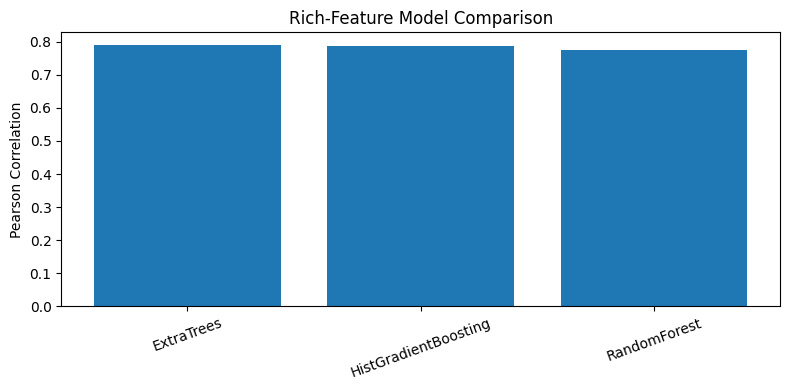

In [22]:
import matplotlib.pyplot as plt

results_plot = results_df.sort_values("pearson", ascending=False)

plt.figure(figsize=(8, 4))
plt.bar(results_plot["model"], results_plot["pearson"])
plt.ylabel("Pearson Correlation")
plt.title("Rich-Feature Model Comparison")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


## 8. Ensemble Learning

Different tree-based models can capture complementary relationships in the acoustic feature space.

Out-of-fold predictions are generated and used to evaluate weighted ensemble combinations.


In [23]:
import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

from sklearn.ensemble import (
    ExtraTreesRegressor,
    RandomForestRegressor,
    HistGradientBoostingRegressor
)

from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mean_absolute_error


# =========================================================
# DATA
# =========================================================

df = train_features.copy()

drop_cols = ["filename", "label"]

feature_cols = [
    c for c in df.columns
    if c not in drop_cols
]

X = df[feature_cols]
y = df["label"].values


# =========================================================
# SAME FOLDS FOR ALL MODELS
# =========================================================

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# =========================================================
# MODELS
# =========================================================

models = {

    "ExtraTrees": make_pipeline(
        SimpleImputer(strategy="median"),
        ExtraTreesRegressor(
            n_estimators=700,
            min_samples_leaf=2,
            max_features=0.8,
            random_state=42,
            n_jobs=-1
        )
    ),

    "HistGradientBoosting": make_pipeline(
        SimpleImputer(strategy="median"),
        HistGradientBoostingRegressor(
            max_iter=300,
            learning_rate=0.04,
            max_leaf_nodes=15,
            l2_regularization=1.0,
            random_state=42
        )
    ),

    "RandomForest": make_pipeline(
        SimpleImputer(strategy="median"),
        RandomForestRegressor(
            n_estimators=700,
            min_samples_leaf=3,
            max_features=0.7,
            random_state=42,
            n_jobs=-1
        )
    )
}


# =========================================================
# OOF PREDICTIONS
# =========================================================

predictions = {}

for name, model in models.items():

    print(f"Training {name}...")

    pred = cross_val_predict(
        model,
        X,
        y,
        cv=cv,
        n_jobs=-1
    )

    predictions[name] = pred

    pearson = pearsonr(y, pred)[0]
    rmse = np.sqrt(mean_squared_error(y, pred))
    mae = mean_absolute_error(y, pred)

    print(
        f"{name:25s}"
        f" Pearson={pearson:.4f}"
        f" | RMSE={rmse:.4f}"
        f" | MAE={mae:.4f}"
    )


# =========================================================
# BLEND SEARCH
# =========================================================

et = predictions["ExtraTrees"]
hgb = predictions["HistGradientBoosting"]
rf = predictions["RandomForest"]

best = None

# Weights are constrained to sum to 1
for w_et in np.arange(0.0, 1.01, 0.05):

    for w_hgb in np.arange(0.0, 1.01 - w_et, 0.05):

        w_rf = 1.0 - w_et - w_hgb

        pred = (
            w_et * et +
            w_hgb * hgb +
            w_rf * rf
        )

        score = pearsonr(y, pred)[0]

        if best is None or score > best["pearson"]:

            best = {
                "w_et": w_et,
                "w_hgb": w_hgb,
                "w_rf": w_rf,
                "pearson": score,
                "rmse": np.sqrt(
                    mean_squared_error(y, pred)
                ),
                "mae": mean_absolute_error(y, pred)
            }


print("\n" + "=" * 60)
print("BEST BLEND")
print("=" * 60)

print(f"ExtraTrees weight           : {best['w_et']:.2f}")
print(f"HistGradientBoosting weight : {best['w_hgb']:.2f}")
print(f"RandomForest weight         : {best['w_rf']:.2f}")
print(f"Pearson                     : {best['pearson']:.4f}")
print(f"RMSE                        : {best['rmse']:.4f}")
print(f"MAE                         : {best['mae']:.4f}")

Training ExtraTrees...
ExtraTrees                Pearson=0.7894 | RMSE=0.7638 | MAE=0.6089
Training HistGradientBoosting...
HistGradientBoosting      Pearson=0.7879 | RMSE=0.7627 | MAE=0.5907
Training RandomForest...
RandomForest              Pearson=0.7764 | RMSE=0.7834 | MAE=0.6260

BEST BLEND
ExtraTrees weight           : 0.55
HistGradientBoosting weight : 0.45
RandomForest weight         : -0.00
Pearson                     : 0.7950
RMSE                        : 0.7535
MAE                         : 0.5934


### 8.1 CatBoost Candidate

CatBoost is evaluated as an additional nonlinear regression model to determine whether it provides complementary information beyond ExtraTrees and Histogram Gradient Boosting.


In [24]:
from catboost import CatBoostRegressor
from sklearn.model_selection import KFold, cross_val_predict
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_absolute_error
from scipy.stats import pearsonr
import numpy as np

df = train_features.copy()

feature_cols = [
    c for c in df.columns
    if c not in ["filename", "label"]
]

X = df[feature_cols]
y = df["label"].values

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

cat_model = make_pipeline(
    SimpleImputer(strategy="median"),
    CatBoostRegressor(
        iterations=1200,
        depth=6,
        learning_rate=0.03,
        l2_leaf_reg=5,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        thread_count=-1
    )
)

cat_pred = cross_val_predict(
    cat_model,
    X,
    y,
    cv=cv,
    n_jobs=1
)

cat_pearson = pearsonr(y, cat_pred)[0]
cat_rmse = np.sqrt(mean_squared_error(y, cat_pred))
cat_mae = mean_absolute_error(y, cat_pred)

print("=" * 50)
print("CATBOOST")
print("=" * 50)
print(f"Pearson : {cat_pearson:.4f}")
print(f"RMSE    : {cat_rmse:.4f}")
print(f"MAE     : {cat_mae:.4f}")

CATBOOST
Pearson : 0.7931
RMSE    : 0.7558
MAE     : 0.6013


### 8.2 Ensemble Weight Search

Weighted combinations of CatBoost, ExtraTrees and Histogram Gradient Boosting are evaluated using their out-of-fold predictions.

The objective is to maximize Pearson Correlation while also monitoring RMSE and MAE.


In [25]:
import numpy as np
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Get the previously generated OOF predictions
et_pred = predictions["ExtraTrees"]
hgb_pred = predictions["HistGradientBoosting"]

# cat_pred was generated by the CatBoost cell

best = None

for w_cat in np.arange(0.0, 0.51, 0.025):

    for w_et in np.arange(0.0, 1.01 - w_cat, 0.025):

        w_hgb = 1.0 - w_cat - w_et

        if w_hgb < 0:
            continue

        pred = (
            w_cat * cat_pred +
            w_et * et_pred +
            w_hgb * hgb_pred
        )

        pearson = pearsonr(y, pred)[0]

        if best is None or pearson > best["pearson"]:

            best = {
                "catboost_weight": w_cat,
                "extratrees_weight": w_et,
                "hgb_weight": w_hgb,
                "pearson": pearson,
                "rmse": np.sqrt(
                    mean_squared_error(y, pred)
                ),
                "mae": mean_absolute_error(y, pred)
            }

print("=" * 60)
print("BEST 3-MODEL BLEND")
print("=" * 60)

print(f"CatBoost weight      : {best['catboost_weight']:.3f}")
print(f"ExtraTrees weight    : {best['extratrees_weight']:.3f}")
print(f"HGB weight           : {best['hgb_weight']:.3f}")
print(f"Pearson              : {best['pearson']:.4f}")
print(f"RMSE                 : {best['rmse']:.4f}")
print(f"MAE                  : {best['mae']:.4f}")

BEST 3-MODEL BLEND
CatBoost weight      : 0.425
ExtraTrees weight    : 0.275
HGB weight           : 0.300
Pearson              : 0.7967
RMSE                 : 0.7507
MAE                  : 0.5936


## 9. Error Analysis

Model predictions are examined to understand where the acoustic ensemble performs well and where errors are concentrated.

The zero-score recordings are analyzed separately because they form a distinct group in the training data.


In [26]:
import numpy as np
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Current clean blend
blend_pred = (
    0.55 * predictions["ExtraTrees"] +
    0.45 * predictions["HistGradientBoosting"]
)

df_eval = train_features[[
    "filename",
    "label"
]].copy()

df_eval["prediction"] = blend_pred
df_eval["error"] = df_eval["prediction"] - df_eval["label"]

# ---------------------------------------------------------
# Overall
# ---------------------------------------------------------

print("=" * 60)
print("CURRENT BLEND")
print("=" * 60)

print(
    "Pearson:",
    round(pearsonr(
        df_eval["label"],
        df_eval["prediction"]
    )[0], 4)
)

print(
    "RMSE:",
    round(np.sqrt(
        mean_squared_error(
            df_eval["label"],
            df_eval["prediction"]
        )
    ), 4)
)

print(
    "MAE:",
    round(
        mean_absolute_error(
            df_eval["label"],
            df_eval["prediction"]
        ), 4
    )
)

# ---------------------------------------------------------
# Zero-label samples
# ---------------------------------------------------------

zero = df_eval[df_eval["label"] == 0]
nonzero = df_eval[df_eval["label"] > 0]

print("\n" + "=" * 60)
print("ZERO-SCORE SAMPLES")
print("=" * 60)

print("Number of zero samples:", len(zero))

print(
    "\nMean prediction for zero samples:",
    round(zero["prediction"].mean(), 4)
)

print(
    "Median prediction:",
    round(zero["prediction"].median(), 4)
)

print(
    "Min prediction:",
    round(zero["prediction"].min(), 4)
)

print(
    "Max prediction:",
    round(zero["prediction"].max(), 4)
)

print(
    "\nRMSE on zero samples:",
    round(
        np.sqrt(
            mean_squared_error(
                zero["label"],
                zero["prediction"]
            )
        ), 4
    )
)

# ---------------------------------------------------------
# Non-zero samples
# ---------------------------------------------------------

print("\n" + "=" * 60)
print("NON-ZERO SAMPLES")
print("=" * 60)

print("Number:", len(nonzero))

print(
    "RMSE:",
    round(
        np.sqrt(
            mean_squared_error(
                nonzero["label"],
                nonzero["prediction"]
            )
        ), 4
    )
)

print(
    "Mean absolute error:",
    round(
        mean_absolute_error(
            nonzero["label"],
            nonzero["prediction"]
        ), 4
    )
)

# ---------------------------------------------------------
# Zero-label feature comparison
# ---------------------------------------------------------

feature_check = [
    "duration",
    "rms_global",
    "peak",
    "crest_factor",
    "active_ratio",
    "zcr_mean",
    "zcr_std",
    "centroid_mean",
    "bandwidth_mean",
    "pitch_mean",
    "pitch_std"
]

available = [
    c for c in feature_check
    if c in train_features.columns
]

print("\n" + "=" * 60)
print("ZERO VS NON-ZERO FEATURE MEANS")
print("=" * 60)

comparison = pd.DataFrame({
    "zero_mean": train_features[
        train_features["label"] == 0
    ][available].mean(),

    "nonzero_mean": train_features[
        train_features["label"] > 0
    ][available].mean()
})

comparison["difference_%"] = (
    (comparison["zero_mean"] -
     comparison["nonzero_mean"])
    /
    (comparison["nonzero_mean"].abs() + 1e-8)
) * 100

display(comparison.round(4))

CURRENT BLEND
Pearson: 0.795
RMSE: 0.7535
MAE: 0.5934

ZERO-SCORE SAMPLES
Number of zero samples: 37

Mean prediction for zero samples: 0.0276
Median prediction: 0.0059
Min prediction: -0.018
Max prediction: 0.3063

RMSE on zero samples: 0.0736

NON-ZERO SAMPLES
Number: 732
RMSE: 0.7721
Mean absolute error: 0.6216

ZERO VS NON-ZERO FEATURE MEANS


,zero_mean,nonzero_mean,difference_%
duration,57.8642,55.6758,3.9306
rms_global,0.1220,0.0575,111.9245
peak,0.9500,0.7433,27.8024
crest_factor,8.1274,13.6843,-40.6078
active_ratio,0.4062,0.1321,207.4448
zcr_mean,0.4546,0.1466,210.1600
zcr_std,0.0595,0.1119,-46.8752
centroid_mean,3870.4654,1783.9379,116.9619
bandwidth_mean,2349.3122,1534.7660,53.0730
pitch_mean,133.5423,169.9422,-21.4190


### 9.1 Prediction Post-processing

Several prediction transformations are compared:

- Raw predictions
- Clipping to the valid 0–5 range
- Linear calibration
- Rounding to the nearest 0.5

Pearson Correlation, RMSE and MAE are used to compare these strategies.


In [27]:
import numpy as np
from scipy.stats import pearsonr
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Current OOF blend
oof = (
    0.55 * predictions["ExtraTrees"] +
    0.45 * predictions["HistGradientBoosting"]
)

y_true = y.copy()

def report(name, pred):
    print(f"\n{name}")
    print("-" * 50)
    print(f"Pearson : {pearsonr(y_true, pred)[0]:.6f}")
    print(f"RMSE    : {np.sqrt(mean_squared_error(y_true, pred)):.6f}")
    print(f"MAE     : {mean_absolute_error(y_true, pred):.6f}")

# ---------------------------------------------------------
# 1. Current
# ---------------------------------------------------------

report("Original", oof)

# ---------------------------------------------------------
# 2. Clip to valid 0-5 range
# ---------------------------------------------------------

clipped = np.clip(oof, 0, 5)

report("Clipped [0,5]", clipped)

# ---------------------------------------------------------
# 3. Linear calibration using OOF predictions
# ---------------------------------------------------------

# Fit y = a * prediction + b
a, b = np.polyfit(oof, y_true, 1)

calibrated = a * oof + b
calibrated = np.clip(calibrated, 0, 5)

print("\nCalibration:")
print("a =", a)
print("b =", b)

report("Calibrated + clipped", calibrated)

# ---------------------------------------------------------
# 4. Round to nearest 0.5
# ---------------------------------------------------------

rounded = np.round(clipped * 2) / 2

report("Rounded to nearest 0.5", rounded)


Original
--------------------------------------------------
Pearson : 0.795018
RMSE    : 0.753499
MAE     : 0.593390

Clipped [0,5]
--------------------------------------------------
Pearson : 0.795052
RMSE    : 0.753497
MAE     : 0.593207

Calibration:
a = 1.0645007013601753
b = -0.20327697270383166

Calibrated + clipped
--------------------------------------------------
Pearson : 0.796154
RMSE    : 0.749953
MAE     : 0.584019

Rounded to nearest 0.5
--------------------------------------------------
Pearson : 0.784749
RMSE    : 0.768360
MAE     : 0.585176


### 9.2 Cross-Validated Calibration

Calibration is evaluated using an additional five-fold procedure to reduce the risk of overestimating its benefit.

The final calibration parameters are estimated from the out-of-fold predictions and applied to the final test predictions.


In [28]:
import numpy as np
from scipy.stats import pearsonr
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error


# =========================================================
# Predictions
# =========================================================

et = predictions["ExtraTrees"]
hgb = predictions["HistGradientBoosting"]
cat = cat_pred

y_true = y.copy()

pred_2model = (
    0.55 * et +
    0.45 * hgb
)

pred_3model = (
    0.425 * cat +
    0.275 * et +
    0.300 * hgb
)


# =========================================================
# Cross-validated calibration
# =========================================================

def cross_validated_calibration(pred, y, name):

    cv_cal = KFold(
        n_splits=5,
        shuffle=True,
        random_state=42
    )

    calibrated_oof = np.zeros(len(y))

    for train_idx, val_idx in cv_cal.split(pred):

        calibrator = LinearRegression()

        calibrator.fit(
            pred[train_idx].reshape(-1, 1),
            y[train_idx]
        )

        calibrated_oof[val_idx] = calibrator.predict(
            pred[val_idx].reshape(-1, 1)
        )

    calibrated_oof = np.clip(
        calibrated_oof,
        0,
        5
    )

    pearson = pearsonr(
        y,
        calibrated_oof
    )[0]

    rmse = np.sqrt(
        mean_squared_error(
            y,
            calibrated_oof
        )
    )

    mae = mean_absolute_error(
        y,
        calibrated_oof
    )

    print("\n" + "=" * 60)
    print(name)
    print("=" * 60)
    print(f"Pearson : {pearson:.6f}")
    print(f"RMSE    : {rmse:.6f}")
    print(f"MAE     : {mae:.6f}")

    # Fit final calibrator on ALL OOF predictions
    final_calibrator = LinearRegression()

    final_calibrator.fit(
        pred.reshape(-1, 1),
        y
    )

    print(
        f"Final calibration slope     : "
        f"{final_calibrator.coef_[0]:.6f}"
    )

    print(
        f"Final calibration intercept : "
        f"{final_calibrator.intercept_:.6f}"
    )

    return final_calibrator


calibrator_2 = cross_validated_calibration(
    pred_2model,
    y_true,
    "55/45 ExtraTrees + HGB"
)

calibrator_3 = cross_validated_calibration(
    pred_3model,
    y_true,
    "3-Model Blend"
)


55/45 ExtraTrees + HGB
Pearson : 0.794861
RMSE    : 0.751987
MAE     : 0.585248
Final calibration slope     : 1.064501
Final calibration intercept : -0.203277

3-Model Blend
Pearson : 0.796673
RMSE    : 0.749049
MAE     : 0.584802
Final calibration slope     : 1.063514
Final calibration intercept : -0.202145


### 9.3 Prediction Diagnostics


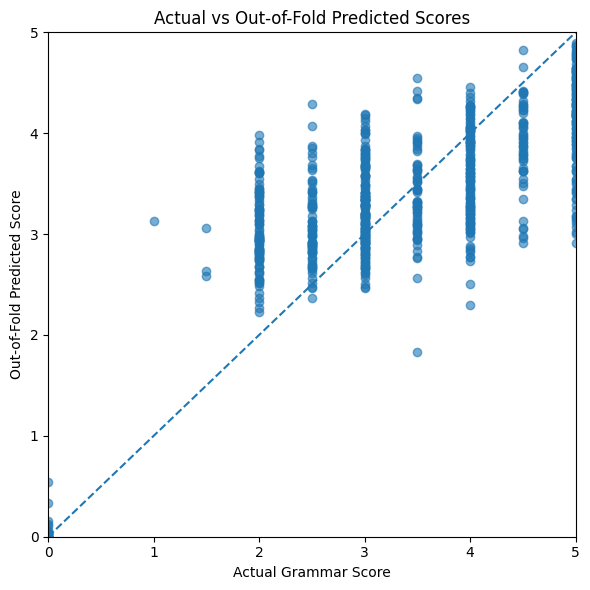

In [29]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 6))
plt.scatter(y, pred_3model, alpha=0.6)
plt.xlabel("Actual Grammar Score")
plt.ylabel("Out-of-Fold Predicted Score")
plt.title("Actual vs Out-of-Fold Predicted Scores")
plt.plot([0, 5], [0, 5], linestyle="--")
plt.xlim(0, 5)
plt.ylim(0, 5)
plt.tight_layout()
plt.show()


## 10. Original Acoustic-Only Model and Prediction Pipeline

This section documents the first full model pipeline, built from engineered acoustic features only. It is retained as the baseline for the later multimodal experiments.

The acoustic ensemble combines:

- CatBoost: **42.5%**
- ExtraTrees: **27.5%**
- Histogram Gradient Boosting: **30.0%**

The original acoustic predictions are transformed using the evaluated linear calibration and clipped to the valid 0–5 range. Predictions are generated for the 216 evaluation recordings.


In [ ]:
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.ensemble import (
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from sklearn.linear_model import LinearRegression
from catboost import CatBoostRegressor


# =========================================================
# 1. DATA
# =========================================================

train_df = train_features.copy()
test_df = test_features.copy()

feature_cols = [
    c for c in train_df.columns
    if c not in ["filename", "label"]
]

X_train = train_df[feature_cols]
y_train = train_df["label"].values

X_test = test_df[feature_cols]


# =========================================================
# 2. IMPUTATION
# =========================================================

imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)


# =========================================================
# 3. EXTRATREES
# =========================================================

print("Training ExtraTrees...")

et_model = ExtraTreesRegressor(
    n_estimators=1000,
    min_samples_leaf=2,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

et_model.fit(
    X_train_imp,
    y_train
)

et_pred = et_model.predict(X_test_imp)


# =========================================================
# 4. HISTOGRAM GRADIENT BOOSTING
# =========================================================

print("Training HistGradientBoosting...")

hgb_model = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.04,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

hgb_model.fit(
    X_train_imp,
    y_train
)

hgb_pred = hgb_model.predict(X_test_imp)


# =========================================================
# 5. CATBOOST
# =========================================================

print("Training CatBoost...")

cat_model = CatBoostRegressor(
    iterations=1200,
    depth=6,
    learning_rate=0.03,
    l2_leaf_reg=5,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    thread_count=-1
)

cat_model.fit(
    X_train_imp,
    y_train
)

cat_pred = cat_model.predict(X_test_imp)


# =========================================================
# 6. WEIGHTED ENSEMBLE
# =========================================================

raw_prediction = (
    0.425 * cat_pred +
    0.275 * et_pred +
    0.300 * hgb_pred
)


# =========================================================
# 7. VALIDATED CALIBRATION
# =========================================================
# Learned from out-of-fold predictions:
# slope     = 1.063514
# intercept = -0.202145

calibrated_prediction = (
    1.063514 * raw_prediction
    - 0.202145
)


# =========================================================
# 8. VALID SCORE RANGE
# =========================================================

final_prediction = np.clip(
    calibrated_prediction,
    0,
    5
)


# =========================================================
# 9. SUBMISSION
# =========================================================

submission = pd.DataFrame({
    "filename": test_df["filename"],
    "label": final_prediction
})

submission_path = (
    "/kaggle/working/"
    "submission_01_acoustic_ensemble.csv"
)

submission.to_csv(
    submission_path,
    index=False
)


# =========================================================
# 10. CHECK
# =========================================================

print("\n" + "=" * 60)
print("SUBMISSION CREATED")
print("=" * 60)

print("File:", submission_path)
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())

print("\nPrediction statistics:")
print(submission["label"].describe())

print("\nFirst 10 predictions:")
display(submission.head(10))

print("\nPrediction range:")
print(
    submission["label"].min(),
    "to",
    submission["label"].max()
)

### 10.1 Required Training RMSE

The competition instructions require the RMSE of the training data to be included in the final notebook. The following cell reports the **in-sample training RMSE** of the final calibrated ensemble. This is distinct from the five-fold out-of-fold validation metrics reported earlier.


In [31]:
import numpy as np
from sklearn.metrics import mean_squared_error

train_et_pred = et_model.predict(X_train_imp)
train_hgb_pred = hgb_model.predict(X_train_imp)
train_cat_pred = cat_model.predict(X_train_imp)

train_raw_prediction = (
    0.425 * train_cat_pred +
    0.275 * train_et_pred +
    0.300 * train_hgb_pred
)

train_calibrated_prediction = (
    calibrator_3.coef_[0] * train_raw_prediction +
    calibrator_3.intercept_
)

train_final_prediction = np.clip(
    train_calibrated_prediction,
    0,
    5
)

train_rmse = np.sqrt(
    mean_squared_error(
        y_train,
        train_final_prediction
    )
)

print("Training RMSE (in-sample):", round(train_rmse, 6))


Training RMSE (in-sample): 0.045222


## 11. Original Acoustic Submission Validation

The original acoustic-only submission is checked for:

- Correct row count
- Correct column names
- Exact filename ordering
- Missing predictions
- Duplicate filenames
- Valid prediction range

The later multimodal submission is validated separately in the final submission-generation section.


In [32]:
print("Shape:", submission.shape)
print("Columns:", submission.columns.tolist())
print("Filename order matches test:", submission["filename"].equals(test["filename"]))
print("Missing predictions:", submission["label"].isna().sum())

print("\nDuplicate filenames:", submission["filename"].duplicated().sum())
print("Prediction min:", submission["label"].min())
print("Prediction max:", submission["label"].max())


Shape: (216, 2)
Columns: ['filename', 'label']
Filename order matches test: True
Missing predictions: 0

Duplicate filenames: 0
Prediction min: 2.1521156615578034
Prediction max: 4.751230965622628


## 12. Original Acoustic-Only Baseline Results

### Cross-Validated Performance

The original three-model acoustic ensemble achieved the following five-fold out-of-fold performance:

| Metric | Score |
|---|---:|
| Pearson Correlation | **0.7967** |
| RMSE | **0.7490** |
| MAE | **0.5848** |

### Original Acoustic Pipeline

```text
Audio
  ↓
Audio preprocessing
  ↓
Rich acoustic feature engineering
  ↓
221-column feature table (including filename and label)
  ↓
CatBoost (42.5%) + ExtraTrees (27.5%) + HistGradientBoosting (30.0%)
  ↓
Weighted ensemble
  ↓
Linear calibration
  ↓
Clip to [0, 5]
  ↓
Grammar-score prediction
```

### Role in the Experiments

This acoustic-only result is the baseline for the later experiments. The remaining sections examine train–test distribution shift, a robust acoustic feature subset, Whisper transcription, linguistic features, and a combined acoustic–linguistic model. The latest multimodal results and submission details are summarized at the end of the notebook.


## 13. Train–Test Distribution Shift Analysis

A domain classifier is trained to distinguish labelled training examples from evaluation examples using the engineered acoustic features. Cross-validated ROC-AUC estimates how readily the two feature distributions can be distinguished. A higher score indicates a greater distribution difference and motivates caution when interpreting validation results.

In [33]:
# ============================================================
# TRAIN vs TEST DISTRIBUTION SHIFT ANALYSIS
# ============================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.ensemble import ExtraTreesClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline


# ------------------------------------------------------------
# Prepare train/test feature matrices
# ------------------------------------------------------------

train_shift = train_features.copy()
test_shift = test_features.copy()

feature_cols = [
    c for c in train_shift.columns
    if c not in ["filename", "label"]
]

X_train_shift = train_shift[feature_cols].copy()
X_test_shift = test_shift[feature_cols].copy()

# Train = 0, Test = 1
X_domain = pd.concat(
    [X_train_shift, X_test_shift],
    axis=0,
    ignore_index=True
)

y_domain = np.concatenate([
    np.zeros(len(X_train_shift)),
    np.ones(len(X_test_shift))
])


# ------------------------------------------------------------
# Domain classifier
# ------------------------------------------------------------

domain_model = make_pipeline(
    SimpleImputer(strategy="median"),
    ExtraTreesClassifier(
        n_estimators=400,
        min_samples_leaf=5,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    )
)

cv_domain = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

domain_auc = cross_val_score(
    domain_model,
    X_domain,
    y_domain,
    cv=cv_domain,
    scoring="roc_auc",
    n_jobs=-1
)

print("=" * 60)
print("TRAIN vs TEST DISTRIBUTION SHIFT")
print("=" * 60)

print(
    "Domain ROC-AUC:",
    round(domain_auc.mean(), 4),
    "+/-",
    round(domain_auc.std(), 4)
)

print(
    "\nInterpretation:"
    "\n0.50 ≈ train/test look similar"
    "\n0.60–0.70 = moderate shift"
    "\n>0.75 = strong shift"
)

TRAIN vs TEST DISTRIBUTION SHIFT
Domain ROC-AUC: 0.8465 +/- 0.0245

Interpretation:
0.50 ≈ train/test look similar
0.60–0.70 = moderate shift
>0.75 = strong shift


### 13.1 Feature-Wise Distribution Shift

Compare individual acoustic-feature distributions between train and test. The resulting table ranks features by how well each feature alone distinguishes the two splits and reports their means and standard deviations. Treat these statistics as diagnostics, not as evidence that any feature causes the shift.

In [34]:
# ============================================================
# FEATURE-WISE TRAIN vs TEST DISTRIBUTION SHIFT
# ============================================================

from sklearn.metrics import roc_auc_score
from sklearn.model_selection import StratifiedKFold
from sklearn.ensemble import RandomForestClassifier
import numpy as np
import pandas as pd

# ------------------------------------------------------------
# Prepare train/test feature matrices
# ------------------------------------------------------------

drop_cols = ["filename", "label"]

feature_cols = [
    c for c in train_features.columns
    if c not in drop_cols and c in test_features.columns
]

X_train = train_features[feature_cols].copy()
X_test = test_features[feature_cols].copy()

# Combine train + test
X_domain = pd.concat(
    [X_train, X_test],
    axis=0,
    ignore_index=True
)

y_domain = np.concatenate([
    np.zeros(len(X_train)),   # train = 0
    np.ones(len(X_test))      # test = 1
])

# Clean values
X_domain = X_domain.replace(
    [np.inf, -np.inf],
    np.nan
).fillna(0)

# ------------------------------------------------------------
# Measure univariate distribution shift
# ------------------------------------------------------------

shift_results = []

for col in feature_cols:

    x = X_domain[col].values

    try:
        auc = roc_auc_score(y_domain, x)

        # AUC below 0.5 is equally strong after inversion
        shift_auc = max(auc, 1 - auc)

        train_mean = X_train[col].mean()
        test_mean = X_test[col].mean()

        train_std = X_train[col].std()
        test_std = X_test[col].std()

        shift_results.append({
            "feature": col,
            "domain_auc": shift_auc,
            "train_mean": train_mean,
            "test_mean": test_mean,
            "mean_difference": abs(train_mean - test_mean),
            "train_std": train_std,
            "test_std": test_std
        })

    except Exception:
        pass

shift_df = pd.DataFrame(shift_results)

shift_df = shift_df.sort_values(
    "domain_auc",
    ascending=False
).reset_index(drop=True)

print("=" * 70)
print("TOP FEATURES SHOWING TRAIN/TEST DISTRIBUTION SHIFT")
print("=" * 70)

display(
    shift_df.head(40).round(4)
)

TOP FEATURES SHOWING TRAIN/TEST DISTRIBUTION SHIFT


,feature,domain_auc,train_mean,test_mean,mean_difference,train_std,test_std
0,duration,0.7364,55.7811,48.7553,7.0257,7.9090,8.1816
1,contrast_5_max,0.6832,40.9590,35.6189,5.3400,9.3727,7.4154
2,contrast_5_std,0.6575,5.4766,4.5885,0.8881,1.9431,1.5948
3,contrast_4_max,0.6555,37.4399,34.5934,2.8465,6.7985,5.6322
4,rms_max,0.6456,0.2415,0.1855,0.0560,0.1043,0.1251
5,delta_11_min,0.6397,-6.8302,-6.2245,0.6056,1.6965,1.4333
6,mfcc_3_max,0.6338,106.5999,93.3933,13.2066,35.7108,26.6596
7,flatness_min,0.6338,0.0046,0.0001,0.0045,0.0215,0.0003
8,mfcc_9_max,0.6326,37.8423,32.9293,4.9130,12.4919,9.3032
9,rms_global,0.6294,0.0606,0.0474,0.0132,0.0272,0.0317


## 14. Robust Acoustic Feature Experiment

This experiment removes duration, sample rate, and features ending in `_min` or `_max`, retaining a more compact set of acoustic descriptors. The goal is to test whether a feature subset less dependent on duration and frame-level extrema can retain predictive quality under train–test distribution shift.

Recorded five-fold OOF results for the robust acoustic blend were Pearson **0.7956**, RMSE **0.7514**, and MAE **0.5898**. An earlier experiment reported a robust-feature domain AUC of 1.0000 from in-sample predictions; that value is not a valid generalization estimate. The code in this public copy uses five-fold cross-validation for the domain classifier instead.


In [ ]:
# ============================================================
# EXPERIMENT: ROBUST ACOUSTIC FEATURE SET
# Goal:
#   Reduce train/test distribution sensitivity caused by
#   duration and frame-level extrema while keeping
#   mean/std acoustic information.
# ============================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold, cross_val_predict, StratifiedKFold, cross_val_score
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline

from sklearn.ensemble import (
    ExtraTreesRegressor,
    HistGradientBoostingRegressor,
    ExtraTreesClassifier
)

from catboost import CatBoostRegressor

from sklearn.metrics import (
    mean_squared_error,
    mean_absolute_error,
    roc_auc_score
)

from scipy.stats import pearsonr


# ============================================================
# 1. BUILD ROBUST FEATURE SET
# ============================================================

all_features = [
    c for c in train_features.columns
    if c in test_features.columns
    and c not in ["filename", "label"]
]

robust_features = [
    c for c in all_features
    if c != "duration"
    and c != "sample_rate"
    and not c.endswith("_min")
    and not c.endswith("_max")
]

print("=" * 60)
print("ROBUST FEATURE SET")
print("=" * 60)

print("Original features :", len(all_features))
print("Robust features   :", len(robust_features))

print("\nRemoved features  :", len(all_features) - len(robust_features))


# ============================================================
# 2. TRAINING DATA
# ============================================================

X = train_features[robust_features].copy()
y = train_features["label"].values

X_test = test_features[robust_features].copy()

cv = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)


# ============================================================
# 3. MODELS
# ============================================================

et_model = make_pipeline(
    SimpleImputer(strategy="median"),
    ExtraTreesRegressor(
        n_estimators=700,
        min_samples_leaf=2,
        max_features=0.8,
        random_state=42,
        n_jobs=-1
    )
)

hgb_model = make_pipeline(
    SimpleImputer(strategy="median"),
    HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.04,
        max_leaf_nodes=15,
        l2_regularization=1.0,
        random_state=42
    )
)

cat_model = make_pipeline(
    SimpleImputer(strategy="median"),
    CatBoostRegressor(
        iterations=1200,
        depth=6,
        learning_rate=0.03,
        l2_leaf_reg=5,
        loss_function="RMSE",
        random_seed=42,
        verbose=False,
        thread_count=-1
    )
)


# ============================================================
# 4. OUT-OF-FOLD PREDICTIONS
# ============================================================

print("\nTraining ExtraTrees...")

et_robust = cross_val_predict(
    et_model,
    X,
    y,
    cv=cv,
    n_jobs=-1
)

print("Training HistGradientBoosting...")

hgb_robust = cross_val_predict(
    hgb_model,
    X,
    y,
    cv=cv,
    n_jobs=-1
)

print("Training CatBoost...")

cat_robust = cross_val_predict(
    cat_model,
    X,
    y,
    cv=cv,
    n_jobs=1
)


# ============================================================
# 5. EVALUATION FUNCTION
# ============================================================

def evaluate(name, pred):

    pearson = pearsonr(y, pred)[0]

    rmse = np.sqrt(
        mean_squared_error(y, pred)
    )

    mae = mean_absolute_error(
        y,
        pred
    )

    print(
        f"{name:20s}"
        f" Pearson={pearson:.4f}"
        f" | RMSE={rmse:.4f}"
        f" | MAE={mae:.4f}"
    )

    return {
        "model": name,
        "pearson": pearson,
        "rmse": rmse,
        "mae": mae
    }


# ============================================================
# 6. INDIVIDUAL MODELS
# ============================================================

print("\n" + "=" * 60)
print("ROBUST FEATURE MODEL RESULTS")
print("=" * 60)

robust_results = []

robust_results.append(
    evaluate("ExtraTrees", et_robust)
)

robust_results.append(
    evaluate("HistGradientBoosting", hgb_robust)
)

robust_results.append(
    evaluate("CatBoost", cat_robust)
)


# ============================================================
# 7. SAME WEIGHTS AS CURRENT FINAL MODEL
# ============================================================

robust_blend = (
    0.425 * cat_robust +
    0.275 * et_robust +
    0.300 * hgb_robust
)

robust_results.append(
    evaluate("Robust 3-Model Blend", robust_blend)
)

robust_results_df = pd.DataFrame(
    robust_results
).sort_values(
    "pearson",
    ascending=False
)

print("\nMODEL COMPARISON")
display(robust_results_df)


# ============================================================
# 8. TRAIN vs TEST DOMAIN SHIFT
# ============================================================

X_train_domain = train_features[robust_features].copy()
X_test_domain = test_features[robust_features].copy()

X_domain = pd.concat(
    [X_train_domain, X_test_domain],
    ignore_index=True
)

y_domain = np.concatenate([
    np.zeros(len(X_train_domain)),
    np.ones(len(X_test_domain))
])

domain_model = make_pipeline(
    SimpleImputer(strategy="median"),
    ExtraTreesClassifier(
        n_estimators=400,
        min_samples_leaf=5,
        max_features=0.7,
        random_state=42,
        n_jobs=-1
    )
)

# Estimate domain separability out of sample. An in-sample AUC is not
# a valid estimate of how well the train/test distributions can be separated.
cv_domain = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

domain_auc_scores = cross_val_score(
    domain_model,
    X_domain,
    y_domain,
    cv=cv_domain,
    scoring="roc_auc",
    n_jobs=-1
)

domain_auc_mean = float(domain_auc_scores.mean())
domain_auc_std = float(domain_auc_scores.std())

print("\n" + "=" * 60)
print("ROBUST FEATURE TRAIN/TEST SHIFT (5-FOLD CV)")
print("=" * 60)

print(
    f"Domain ROC-AUC: {domain_auc_mean:.4f} +/- {domain_auc_std:.4f}"
)


# ============================================================
# 9. SUMMARY
# ============================================================

print("\n" + "=" * 60)
print("EXPERIMENT SUMMARY")
print("=" * 60)

print("Previous full-feature CV Pearson : 0.7967")
print("Previous full-feature domain AUC : 0.8465")

print(
    f"Robust-feature blend Pearson    : "
    f"{pearsonr(y, robust_blend)[0]:.4f}"
)

print(
    f"Robust-feature blend RMSE       : "
    f"{np.sqrt(mean_squared_error(y, robust_blend)):.4f}"
)

print(
    f"Robust-feature blend MAE        : "
    f"{mean_absolute_error(y, robust_blend):.4f}"
)

print(
    f"Robust-feature domain ROC-AUC (CV): "
    f"{domain_auc_mean:.4f} +/- {domain_auc_std:.4f}"
)

### 14.1 Train Robust Acoustic Models and Generate Test Predictions

Train ExtraTrees, Histogram Gradient Boosting, and CatBoost on the robust acoustic feature set and blend their test predictions. This is a separate acoustic-only experiment; its output does not replace the original submission unless the validation and leaderboard results justify doing so.


In [ ]:
import numpy as np
import pandas as pd

from sklearn.impute import SimpleImputer
from sklearn.ensemble import (
    ExtraTreesRegressor,
    HistGradientBoostingRegressor
)
from catboost import CatBoostRegressor


# ============================================================
# TRAIN ROBUST MODELS ON ALL TRAINING DATA
# ============================================================

X_train = train_features[robust_features]
y_train = train_features["label"].values

X_test = test_features[robust_features]

imputer = SimpleImputer(strategy="median")

X_train_imp = imputer.fit_transform(X_train)
X_test_imp = imputer.transform(X_test)


# -------------------------
# ExtraTrees
# -------------------------

print("Training ExtraTrees...")

et_final = ExtraTreesRegressor(
    n_estimators=1000,
    min_samples_leaf=2,
    max_features=0.8,
    random_state=42,
    n_jobs=-1
)

et_final.fit(
    X_train_imp,
    y_train
)

et_pred_test = et_final.predict(X_test_imp)


# -------------------------
# HistGradientBoosting
# -------------------------

print("Training HistGradientBoosting...")

hgb_final = HistGradientBoostingRegressor(
    max_iter=300,
    learning_rate=0.04,
    max_leaf_nodes=15,
    l2_regularization=1.0,
    random_state=42
)

hgb_final.fit(
    X_train_imp,
    y_train
)

hgb_pred_test = hgb_final.predict(X_test_imp)


# -------------------------
# CatBoost
# -------------------------

print("Training CatBoost...")

cat_final = CatBoostRegressor(
    iterations=1200,
    depth=6,
    learning_rate=0.03,
    l2_leaf_reg=5,
    loss_function="RMSE",
    random_seed=42,
    verbose=False,
    thread_count=-1
)

cat_final.fit(
    X_train_imp,
    y_train
)

cat_pred_test = cat_final.predict(
    X_test_imp
)


# ============================================================
# ROBUST ENSEMBLE
# ============================================================

robust_prediction = (
    0.425 * cat_pred_test +
    0.275 * et_pred_test +
    0.300 * hgb_pred_test
)

robust_prediction = np.clip(
    robust_prediction,
    0,
    5
)


# ============================================================
# SUBMISSION #2
# ============================================================

submission_02 = pd.DataFrame({
    "filename": test_features["filename"],
    "label": robust_prediction
})

submission_02_path = (
    "/kaggle/working/"
    "submission_02_robust_acoustic.csv"
)

submission_02.to_csv(
    submission_02_path,
    index=False
)


# ============================================================
# CHECK
# ============================================================

print("\n" + "=" * 60)
print("SUBMISSION #2")
print("=" * 60)

print("File:", submission_02_path)
print("Shape:", submission_02.shape)
print("Columns:", submission_02.columns.tolist())

print(
    "Filename order matches test:",
    submission_02["filename"].equals(
        test_features["filename"]
    )
)

print(
    "Missing predictions:",
    submission_02["label"].isna().sum()
)

print(
    "Duplicate filenames:",
    submission_02["filename"].duplicated().sum()
)

print(
    "Prediction range:",
    submission_02["label"].min(),
    "to",
    submission_02["label"].max()
)

display(submission_02.head(10))

## 15. Whisper-Based Speech-to-Text Pipeline

Faster-Whisper is used to transcribe English speech from the training and evaluation recordings. These transcripts are later converted into linguistic features and combined with acoustic features. The following setup cells check GPU and dataset availability, install the transcription dependencies, verify imports, and test transcription before processing all recordings.


In [1]:
import torch
import os
from pathlib import Path

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("No GPU detected. Do not start model downloads yet.")

BASE = Path(
    "/kaggle/input/competitions/"
    "shl-hiring-assessment-2026/Dataset_Final"
)

print("Dataset available:", BASE.exists())
print("Train CSV available:", (BASE / "train.csv").exists())
print("Test CSV available:", (BASE / "test.csv").exists())

CUDA available: True
GPU: Tesla T4
Dataset available: True
Train CSV available: True
Test CSV available: True


### 15.1 Install Faster-Whisper and Compatible PyAV

Install the pinned transcription dependencies. PyAV is pinned to version 18.1.0 to avoid the incompatibility encountered with the installed Faster-Whisper version. Run this setup cell only when the current Kaggle environment needs these packages.


In [1]:
%pip install --no-cache-dir \
    "av==18.1.0" \
    "faster-whisper==1.2.1"

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.8/35.8 MB 22.0 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.1/1.1 MB 23.7 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 39.6/39.6 MB 21.6 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.6/23.6 MB 13.0 MB/s eta 0:00:0000:0100:01
Note: you may need to restart the kernel to use updated packages.


### 15.2 Verify the Transcription Environment

Confirm that PyAV and Faster-Whisper import correctly and that CUDA is available. The test does not require a Hugging Face token when model downloads are available anonymously; the token warning by itself is not a transcription failure.


In [2]:
import sys
import numpy as np
import av
import torch
from importlib.metadata import version
from faster_whisper import WhisperModel

print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("PyAV:", av.__version__)
print("faster-whisper:", version("faster-whisper"))
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

assert av.__version__ == "18.1.0"
assert version("faster-whisper") == "1.2.1"

print("\nPackage verification passed.")

Python: /usr/bin/python3
NumPy: 2.1.3
PyAV: 18.1.0
faster-whisper: 1.2.1
CUDA available: True
GPU: Tesla T4

Package verification passed.


### 15.3 Smoke Test One Training and One Evaluation Recording

Load the English Whisper Small model on the GPU and transcribe one labelled training recording plus one evaluation recording. This verifies audio access and inference before committing time to the complete dataset.


In [ ]:
from pathlib import Path
import pandas as pd
from faster_whisper import WhisperModel

# Dataset paths
DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)

TRAIN_DIR = DATA_DIR / "train"
TEST_DIR = DATA_DIR / "test"

train_df = pd.read_csv(DATA_DIR / "train.csv")
test_df = pd.read_csv(DATA_DIR / "test.csv")

# Select one training and one test recording
train_path = TRAIN_DIR / str(train_df.iloc[0]["filename"])
test_path = TEST_DIR / str(test_df.iloc[0]["filename"])

assert train_path.exists(), f"Training audio not found: {train_path}"
assert test_path.exists(), f"Test audio not found: {test_path}"

print("Training sample:", train_path.name)
print("Test sample:", test_path.name)

# Load Whisper Small English on the Tesla T4 GPU
whisper_model = WhisperModel(
    "small.en",
    device="cuda",
    compute_type="float16"
)

def transcribe_one(path):
    segments, info = whisper_model.transcribe(
        str(path),
        language="en",
        beam_size=3,
        vad_filter=True,
        word_timestamps=True
    )

    # Consume the generator to complete transcription
    segments = list(segments)

    transcript = " ".join(
        segment.text.strip()
        for segment in segments
    ).strip()

    return transcript, info, segments

for label, path in [
    ("TRAINING AUDIO", train_path),
    ("TEST AUDIO", test_path),
]:
    print(f"\n{'=' * 20} {label} {'=' * 20}")

    transcript, info, segments = transcribe_one(path)

    print("Detected language:", info.language)
    print("Audio duration:", round(info.duration, 2), "seconds")
    print("Number of segments:", len(segments))
    print("Transcript character count:", len(transcript))
    print("Transcription successful:", bool(transcript))

### 15.4 Transcribe All Recordings with Checkpointing

Transcribe the full set of 769 training and 216 evaluation recordings. Store each completed transcript, segment, timestamp, and confidence value in a JSONL checkpoint so that completed work can be reused after an interruption. Train labels are retained only for training examples; evaluation labels remain placeholders.


In [4]:

from pathlib import Path
import json
from tqdm.auto import tqdm

# Persistent checkpoint file in the Kaggle working directory
CACHE_PATH = Path("/kaggle/working/whisper_transcripts.jsonl")

jobs = []
for _, row in train_df.iterrows():
    jobs.append({
        "split": "train",
        "filename": str(row["filename"]),
        "label": float(row["label"]),
        "path": TRAIN_DIR / str(row["filename"]),
    })

for _, row in test_df.iterrows():
    jobs.append({
        "split": "test",
        "filename": str(row["filename"]),
        "label": -1,
        "path": TEST_DIR / str(row["filename"]),
    })

# Load previously completed transcriptions so reruns can resume
completed = {}
if CACHE_PATH.exists():
    with CACHE_PATH.open("r", encoding="utf-8") as f:
        for line in f:
            try:
                record = json.loads(line)
                if record.get("status") == "ok":
                    completed[(record["split"], record["filename"])] = record
            except (json.JSONDecodeError, KeyError):
                continue

pending = [
    job for job in jobs
    if (job["split"], job["filename"]) not in completed
]

print("Total recordings:", len(jobs))
print("Already transcribed:", len(completed))
print("Remaining:", len(pending))
print("Checkpoint:", CACHE_PATH)

# Append after each recording so completed work is not lost
with CACHE_PATH.open("a", encoding="utf-8") as fout:
    for job in tqdm(pending, desc="Whisper transcription"):
        record = {
            "split": job["split"],
            "filename": job["filename"],
            "label": job["label"],
        }

        try:
            segments, info = whisper_model.transcribe(
                str(job["path"]),
                language="en",
                beam_size=3,
                vad_filter=True,
                word_timestamps=True,
            )

            saved_segments = []
            text_parts = []

            for seg in segments:
                text_parts.append(seg.text.strip())

                words = []
                if seg.words:
                    for word in seg.words:
                        words.append({
                            "text": word.word,
                            "start": float(word.start),
                            "end": float(word.end),
                            "probability": float(word.probability),
                        })

                saved_segments.append({
                    "start": float(seg.start),
                    "end": float(seg.end),
                    "text": seg.text.strip(),
                    "avg_logprob": float(seg.avg_logprob),
                    "no_speech_prob": float(seg.no_speech_prob),
                    "words": words,
                })

            transcript = " ".join(
                part for part in text_parts if part
            ).strip()

            record.update({
                "status": "ok" if transcript else "empty",
                "transcript": transcript,
                "audio_duration": float(info.duration),
                "language": info.language,
                "segments": saved_segments,
            })

        except Exception as exc:
            record.update({
                "status": "error",
                "error": repr(exc),
            })

        fout.write(json.dumps(record, ensure_ascii=False) + "\n")
        fout.flush()

        if record["status"] == "ok":
            completed[(job["split"], job["filename"])] = record

print("\nTranscription run finished.")
print("Successful cached transcripts:", len(completed))
print("Checkpoint file size (MB):", round(CACHE_PATH.stat().st_size / 1e6, 2))
print("Cache path:", CACHE_PATH)


Total recordings: 985
Already transcribed: 0
Remaining: 985
Checkpoint: /kaggle/working/whisper_transcripts.jsonl


Whisper transcription:   0%|          | 0/985 [00:00<?, ?it/s]


Transcription run finished.
Successful cached transcripts: 985
Checkpoint file size (MB): 9.78
Cache path: /kaggle/working/whisper_transcripts.jsonl


## 16. Linguistic Feature Engineering and Text-Only Evaluation

Load the saved Whisper transcripts and extract fixed-length text and timing features, including lexical diversity, word and sentence lengths, function-word rates, repetitions, disfluencies, speech rate, pause statistics, and Whisper confidence summaries. Save the resulting feature table and compare text-only regressors using five-fold cross-validation.


In [5]:
import json
import re
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from catboost import CatBoostRegressor


# --------------------------------------------------
# 1. Load the completed Whisper cache
# --------------------------------------------------
CACHE_PATH = Path("/kaggle/working/whisper_transcripts.jsonl")

records = []
with CACHE_PATH.open("r", encoding="utf-8") as f:
    for line in f:
        if line.strip():
            records.append(json.loads(line))

cache_df = pd.DataFrame(records)

if "status" in cache_df.columns:
    cache_df = cache_df[cache_df["status"] == "ok"].copy()

assert len(cache_df) == 985, (
    f"Expected 985 successful transcriptions, found {len(cache_df)}"
)

print("Loaded successful transcripts:", len(cache_df))
print("Train records:", (cache_df["split"] == "train").sum())
print("Test records:", (cache_df["split"] == "test").sum())


# --------------------------------------------------
# 2. Linguistic feature extraction helpers
# --------------------------------------------------
WORD_PATTERN = re.compile(r"[a-z]+(?:'[a-z]+)?")

STOP_WORDS = set("""
a an the and or but if while because as of at by for with about against
between into through during before after above below to from up down in out
on off over under again further then once is am are was were be been being
have has had do does did will would shall should can could may might must
i me my mine we us our ours you your yours he him his she her hers it its
they them their theirs this that these those who whom which what where when
why how not no nor so than too very just also only own same all any both
each few more most other some such no nor
""".split())

FILLERS = {
    "uh", "um", "erm", "hmm", "ah", "uhh", "umm"
}

PRONOUNS = set("""
i me my mine we us our ours you your yours he him his she her hers
it its they them their theirs this that these those who whom which what
""".split())

ARTICLES = {"a", "an", "the"}
AUXILIARIES = {
    "am", "is", "are", "was", "were", "be", "been", "being",
    "have", "has", "had", "do", "does", "did",
    "will", "would", "shall", "should", "can", "could",
    "may", "might", "must"
}
CONNECTORS = {
    "and", "but", "or", "because", "although", "though", "if",
    "when", "while", "so", "therefore", "however", "since"
}
PREPOSITIONS = set("""
about above across after against along among around at before behind
below beneath beside between beyond by despite down during except for
from in inside into near of off on onto opposite out outside over
past through throughout to toward under underneath until up upon with
within without
""".split())


def safe_float(value):
    try:
        x = float(value)
        return x if np.isfinite(x) else np.nan
    except (TypeError, ValueError):
        return np.nan


def ratio(a, b):
    return float(a / b) if b else 0.0


def syllable_count(word):
    """Approximate English syllables without a pronunciation library."""
    word = re.sub(r"[^a-z]", "", word.lower())
    if not word:
        return 0

    groups = re.findall(r"[aeiouy]+", word)
    count = len(groups)

    if word.endswith("e") and count > 1 and not word.endswith(("le", "ye")):
        count -= 1

    return max(1, count)


def extract_features(record):
    text = str(record.get("transcript", "") or "")
    text_lower = text.lower()

    words = WORD_PATTERN.findall(text_lower)
    n_words = len(words)
    counts = Counter(words)
    unique_words = len(counts)

    # Split on sentence-ending punctuation emitted by Whisper.
    sentences = [
        s.strip()
        for s in re.split(r"[.!?]+", text)
        if WORD_PATTERN.findall(s.lower())
    ]

    sentence_lengths = [
        len(WORD_PATTERN.findall(s.lower())) for s in sentences
    ]

    if not sentence_lengths and n_words:
        sentence_lengths = [n_words]

    n_sentences = len(sentence_lengths)
    word_lengths = [len(w.replace("'", "")) for w in words]
    syllables = [syllable_count(w) for w in words]

    features = {
        "word_count": n_words,
        "character_count": len(text),
        "unique_word_count": unique_words,
        "type_token_ratio": ratio(unique_words, n_words),
        "root_ttr": ratio(unique_words, np.sqrt(n_words)),
        "hapax_ratio": ratio(sum(c == 1 for c in counts.values()), n_words),
        "mean_word_length": np.mean(word_lengths) if word_lengths else 0,
        "std_word_length": np.std(word_lengths) if word_lengths else 0,
        "long_word_ratio_6": ratio(sum(len(w) >= 6 for w in words), n_words),
        "long_word_ratio_8": ratio(sum(len(w) >= 8 for w in words), n_words),
        "mean_syllables": np.mean(syllables) if syllables else 0,
        "mean_sentence_length": (
            np.mean(sentence_lengths) if sentence_lengths else 0
        ),
        "std_sentence_length": (
            np.std(sentence_lengths) if sentence_lengths else 0
        ),
        "max_sentence_length": (
            max(sentence_lengths) if sentence_lengths else 0
        ),
        "sentence_count": n_sentences,
        "words_per_sentence": ratio(n_words, n_sentences),
        "punctuation_count": sum(text.count(p) for p in ".,!?;:"),
        "comma_count": text.count(","),
        "question_mark_count": text.count("?"),
        "exclamation_count": text.count("!"),
        "contraction_count": len(re.findall(
            r"\b[a-z]+n't\b|\b[a-z]+'(?:re|ve|ll|d|m|s)\b",
            text_lower
        )),
        "repeated_adjacent_word_ratio": ratio(
            sum(words[i] == words[i - 1] for i in range(1, n_words)),
            n_words
        ),
        "distinct_bigram_ratio": ratio(
            len(set(zip(words[:-1], words[1:]))),
            max(0, n_words - 1)
        ),
        "filler_ratio": ratio(sum(w in FILLERS for w in words), n_words),
        "stopword_ratio": ratio(sum(w in STOP_WORDS for w in words), n_words),
        "pronoun_ratio": ratio(sum(w in PRONOUNS for w in words), n_words),
        "article_ratio": ratio(sum(w in ARTICLES for w in words), n_words),
        "auxiliary_ratio": ratio(sum(w in AUXILIARIES for w in words), n_words),
        "connector_ratio": ratio(sum(w in CONNECTORS for w in words), n_words),
        "preposition_ratio": ratio(sum(w in PREPOSITIONS for w in words), n_words),
        "past_ed_ratio": ratio(sum(w.endswith("ed") and len(w) > 3 for w in words), n_words),
        "ing_ratio": ratio(sum(w.endswith("ing") and len(w) > 4 for w in words), n_words),
        "third_person_s_ratio": ratio(
            sum(w.endswith("s") and len(w) > 2 for w in words), n_words
        ),
        "because_count": words.count("because"),
        "and_count": words.count("and"),
        "but_count": words.count("but"),
        "so_count": words.count("so"),
        "like_count": words.count("like"),
        "you_know_count": len(re.findall(r"\byou know\b", text_lower)),
        "i_mean_count": len(re.findall(r"\bi mean\b", text_lower)),
        "starts_with_connector": float(
            bool(words) and words[0] in CONNECTORS
        ),
        "starts_with_because": float(bool(words) and words[0] == "because"),
        "digit_count": sum(c.isdigit() for c in text),
        "uppercase_ratio": ratio(
            sum(c.isupper() for c in text),
            sum(c.isalpha() for c in text)
        ),
    }

    # Audio duration and Whisper segment statistics.
    duration = safe_float(record.get("audio_duration"))
    features["audio_duration"] = duration
    features["transcript_words_per_minute"] = (
        ratio(n_words * 60, duration)
        if np.isfinite(duration) and duration > 0 else np.nan
    )

    segments = record.get("segments") or []
    features["segment_count"] = len(segments)

    segment_logprobs = [
        safe_float(s.get("avg_logprob"))
        for s in segments
        if s.get("avg_logprob") is not None
    ]
    segment_logprobs = [x for x in segment_logprobs if np.isfinite(x)]

    no_speech_probs = [
        safe_float(s.get("no_speech_prob"))
        for s in segments
        if s.get("no_speech_prob") is not None
    ]
    no_speech_probs = [x for x in no_speech_probs if np.isfinite(x)]

    features["mean_segment_logprob"] = (
        np.mean(segment_logprobs) if segment_logprobs else np.nan
    )
    features["std_segment_logprob"] = (
        np.std(segment_logprobs) if segment_logprobs else np.nan
    )
    features["mean_no_speech_prob"] = (
        np.mean(no_speech_probs) if no_speech_probs else np.nan
    )

    # Word timestamps: confidence, speaking duration, and pauses.
    timed_words = []
    word_probs = []

    for segment in segments:
        for word in segment.get("words") or []:
            start = safe_float(word.get("start"))
            end = safe_float(word.get("end"))
            probability = safe_float(word.get("probability"))

            if np.isfinite(probability):
                word_probs.append(probability)

            if np.isfinite(start) and np.isfinite(end) and end >= start:
                timed_words.append((start, end))

    timed_words.sort(key=lambda x: x[0])

    features["mean_word_probability"] = (
        np.mean(word_probs) if word_probs else np.nan
    )
    features["std_word_probability"] = (
        np.std(word_probs) if word_probs else np.nan
    )
    features["timed_word_count"] = len(timed_words)

    if timed_words:
        speech_duration = sum(end - start for start, end in timed_words)
        gaps = [
            max(0.0, timed_words[i][0] - timed_words[i - 1][1])
            for i in range(1, len(timed_words))
        ]

        features["estimated_speech_ratio"] = (
            min(1.0, ratio(speech_duration, duration))
            if np.isfinite(duration) and duration > 0 else np.nan
        )
        features["mean_word_gap"] = np.mean(gaps) if gaps else 0.0
        features["std_word_gap"] = np.std(gaps) if gaps else 0.0
        features["max_word_gap"] = max(gaps) if gaps else 0.0
        features["gaps_over_0_5s"] = sum(g > 0.5 for g in gaps)
        features["gaps_over_1s"] = sum(g > 1.0 for g in gaps)
    else:
        features["estimated_speech_ratio"] = np.nan
        features["mean_word_gap"] = np.nan
        features["std_word_gap"] = np.nan
        features["max_word_gap"] = np.nan
        features["gaps_over_0_5s"] = np.nan
        features["gaps_over_1s"] = np.nan

    # Function-word rates, kept separately for interpretable patterns.
    for word in [
        "the", "a", "an", "is", "are", "was", "were", "have", "has",
        "had", "do", "does", "did", "to", "of", "in", "on", "at",
        "for", "with", "because", "and", "but", "if", "when", "that",
        "which", "who", "i", "we", "you", "he", "she", "they", "it"
    ]:
        features[f"rate_{word}"] = ratio(words.count(word), n_words)

    return features


# --------------------------------------------------
# 3. Build and save a separate feature table
# --------------------------------------------------
feature_rows = []

for _, record in cache_df.iterrows():
    row = {
        "split": record["split"],
        "filename": record["filename"],
    }
    row.update(extract_features(record))
    feature_rows.append(row)

text_features = pd.DataFrame(feature_rows)
text_features = text_features.replace([np.inf, -np.inf], np.nan)

FEATURE_PATH = Path("/kaggle/working/whisper_text_features.csv")
text_features.to_csv(FEATURE_PATH, index=False)

print("\nFeature table:", text_features.shape)
print("Saved to:", FEATURE_PATH)
print("Missing feature values:", int(
    text_features.select_dtypes(include=[np.number]).isna().sum().sum()
))


# --------------------------------------------------
# 4. Prepare training data with labels
# --------------------------------------------------
train_text = text_features[text_features["split"] == "train"].merge(
    train_df[["filename", "label"]],
    on="filename",
    how="left",
    validate="one_to_one"
)

test_text = text_features[text_features["split"] == "test"].copy()

assert len(train_text) == len(train_df) == 769
assert len(test_text) == len(test_df) == 216
assert train_text["label"].notna().all()

feature_cols = [
    c for c in text_features.columns
    if c not in ("split", "filename")
]

X = (
    train_text[feature_cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(train_text[feature_cols].median())
    .fillna(0)
)
y = train_text["label"].to_numpy(dtype=float)

print("Training matrix:", X.shape)
print("Target range:", y.min(), "to", y.max())


# --------------------------------------------------
# 5. Five-fold out-of-fold evaluation
# --------------------------------------------------
cv = KFold(n_splits=5, shuffle=True, random_state=42)

models = {
    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=700,
        max_features=0.85,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42
    ),
    "HistGradientBoosting": HistGradientBoostingRegressor(
        max_iter=300,
        learning_rate=0.04,
        max_leaf_nodes=15,
        l2_regularization=3.0,
        random_state=42
    ),
    "CatBoost": CatBoostRegressor(
        iterations=600,
        depth=6,
        learning_rate=0.03,
        loss_function="RMSE",
        verbose=False,
        random_seed=42,
        thread_count=-1
    ),
}

oof_predictions = {}
results = []

for name, base_model in models.items():
    preds = np.full(len(y), np.nan, dtype=float)

    for fold, (tr_idx, va_idx) in enumerate(cv.split(X, y), start=1):
        model = base_model.__class__(**base_model.get_params())
        model.fit(X.iloc[tr_idx], y[tr_idx])
        preds[va_idx] = model.predict(X.iloc[va_idx])

    preds = np.clip(preds, 0, 5)
    oof_predictions[name] = preds

    results.append({
        "Model": name,
        "Pearson": np.corrcoef(y, preds)[0, 1],
        "RMSE": mean_squared_error(y, preds) ** 0.5,
        "MAE": mean_absolute_error(y, preds),
    })

results_df = pd.DataFrame(results).sort_values(
    "Pearson", ascending=False
)

print("\nTEXT-ONLY CROSS-VALIDATION RESULTS")
print(results_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))

print("\nReference only: your earlier acoustic ensemble had")
print("OOF Pearson around 0.7967 and RMSE around 0.749.")
print("Compare validation methods and splits consistently;")
print("text-only scores do not establish whether text improves a combined model.")

Loaded successful transcripts: 985
Train records: 769
Test records: 216

Feature table: (985, 96)
Saved to: /kaggle/working/whisper_text_features.csv
Missing feature values: 0
Training matrix: (769, 94)
Target range: 0.0 to 5.0

TEXT-ONLY CROSS-VALIDATION RESULTS
               Model  Pearson   RMSE    MAE
          ExtraTrees   0.7936 0.7571 0.5811
            CatBoost   0.7861 0.7689 0.5864
HistGradientBoosting   0.7808 0.7740 0.5848

Reference only: your earlier acoustic ensemble had
OOF Pearson around 0.7967 and RMSE around 0.749.
Compare validation methods and splits consistently;
text-only scores do not establish whether text improves a combined model.


## 17. Persist Acoustic Feature Tables for Multimodal Fusion

The acoustic tables are needed again after the Whisper work. These diagnostic cells inspect the current session and then save the recovered acoustic training and evaluation tables to `/kaggle/working`, so the multimodal experiment can reload the features without repeating acoustic extraction.


In [1]:
import pandas as pd
from pathlib import Path

print("=== Acoustic feature DataFrames in memory ===")

for name, obj in list(globals().items()):
    if isinstance(obj, pd.DataFrame):
        cols = list(obj.columns)
        if (
            "filename" in cols
            and len(obj) in (769, 216, 985)
            and len(cols) > 20
        ):
            numeric_count = len(
                obj.select_dtypes(include="number").columns
            )
            print(
                f"{name}: shape={obj.shape}, "
                f"numeric_columns={numeric_count}"
            )

print("\n=== CSV files in /kaggle/working ===")

for path in sorted(Path("/kaggle/working").glob("*.csv")):
    print(path.name, f"({path.stat().st_size / 1e6:.2f} MB)")

=== Acoustic feature DataFrames in memory ===

=== CSV files in /kaggle/working ===
whisper_text_features.csv (1.00 MB)


### 17.1 Save the Recovered Acoustic Training and Test Features

Identify the acoustic feature DataFrames by row count and presence of the label column, then save them as separate CSV files. The expected shapes are 769 training rows and 216 evaluation rows.


In [3]:
import pandas as pd
from pathlib import Path

working = Path("/kaggle/working")
found = []

for name, obj in list(globals().items()):
    if not isinstance(obj, pd.DataFrame):
        continue
    if "filename" not in obj.columns:
        continue

    numeric_cols = obj.select_dtypes(include="number").shape[1]

    if numeric_cols >= 100 and len(obj) in (216, 769, 985):
        found.append((name, obj.copy()))
        print(
            f"Found: {name} | shape={obj.shape} "
            f"| numeric columns={numeric_cols} "
            f"| label column={'label' in obj.columns}"
        )

train_candidates = [
    (name, df) for name, df in found
    if len(df) == 769 and "label" in df.columns
]

test_candidates = [
    (name, df) for name, df in found
    if len(df) == 216 and "label" not in df.columns
]

if len(train_candidates) == 1 and len(test_candidates) == 1:
    train_name, acoustic_train = train_candidates[0]
    test_name, acoustic_test = test_candidates[0]

    acoustic_train.to_csv(
        working / "train_acoustic_features.csv", index=False
    )
    acoustic_test.to_csv(
        working / "test_acoustic_features.csv", index=False
    )

    print("\nSaved acoustic feature tables successfully.")
    print("Training table:", acoustic_train.shape)
    print("Test table:", acoustic_test.shape)
else:
    print(
        "\nCould not uniquely identify both feature tables. "
        "Check the candidates printed above before saving."
    )

Found: train_features | shape=(769, 221) | numeric columns=220 | label column=True
Found: test_features | shape=(216, 220) | numeric columns=219 | label column=False

Saved acoustic feature tables successfully.
Training table: (769, 221)
Test table: (216, 220)


## 18. Multimodal Ensemble: Acoustic + Linguistic Features

Merge the acoustic and linguistic feature tables by filename within each split. Generate out-of-fold predictions on identical five-fold splits for three acoustic models and the text ExtraTrees model. Compare the acoustic ensemble, text-only model, and blends with multiple text weights using Pearson correlation, RMSE, and MAE.


In [4]:

from pathlib import Path

import numpy as np
import pandas as pd

from sklearn.model_selection import KFold
from sklearn.ensemble import ExtraTreesRegressor, HistGradientBoostingRegressor
from sklearn.metrics import mean_squared_error, mean_absolute_error
from catboost import CatBoostRegressor


# ---------------------------------------------------------
# 1. Load saved acoustic and text features
# ---------------------------------------------------------
WORK_DIR = Path("/kaggle/working")

audio_train = pd.read_csv(WORK_DIR / "train_acoustic_features.csv")
audio_test = pd.read_csv(WORK_DIR / "test_acoustic_features.csv")
text_all = pd.read_csv(WORK_DIR / "whisper_text_features.csv")

# Keep training and test text features separate.
text_train = text_all.loc[text_all["split"] == "train"].drop(
    columns=["split"]
).copy()

text_test = text_all.loc[text_all["split"] == "test"].drop(
    columns=["split"]
).copy()

assert len(audio_train) == 769
assert len(audio_test) == 216
assert len(text_train) == 769
assert len(text_test) == 216

assert audio_train["filename"].is_unique
assert audio_test["filename"].is_unique
assert text_train["filename"].is_unique
assert text_test["filename"].is_unique

# Prefix feature names so the two modalities remain distinct.
audio_cols = [
    c for c in audio_train.columns
    if c not in ["filename", "label"]
]
audio_test_cols = [
    c for c in audio_test.columns
    if c not in ["filename", "label"]
]

assert set(audio_cols) == set(audio_test_cols), (
    "Acoustic train/test feature columns do not match."
)

audio_test = audio_test[["filename"] + audio_cols]

text_cols = [
    c for c in text_train.columns
    if c != "filename"
]
assert set(text_cols) == set(
    c for c in text_test.columns if c != "filename"
), "Text train/test feature columns do not match."

audio_train = audio_train.rename(
    columns={c: f"aud_{c}" for c in audio_cols}
)
audio_test = audio_test.rename(
    columns={c: f"aud_{c}" for c in audio_cols}
)
text_train = text_train.rename(
    columns={c: f"txt_{c}" for c in text_cols}
)
text_test = text_test.rename(
    columns={c: f"txt_{c}" for c in text_cols}
)

audio_cols = [f"aud_{c}" for c in audio_cols]
text_cols = [f"txt_{c}" for c in text_cols]

# Merge by filename within each split, never across train/test.
train_data = audio_train.merge(
    text_train, on="filename", how="inner", validate="one_to_one"
)
test_data = audio_test.merge(
    text_test, on="filename", how="inner", validate="one_to_one"
)

assert len(train_data) == 769
assert len(test_data) == 216
assert train_data["label"].notna().all()

y = train_data["label"].to_numpy(dtype=float)

X_audio = (
    train_data[audio_cols]
    .replace([np.inf, -np.inf], np.nan)
    .apply(pd.to_numeric, errors="coerce")
)
X_text = (
    train_data[text_cols]
    .replace([np.inf, -np.inf], np.nan)
    .apply(pd.to_numeric, errors="coerce")
)

print("Training records:", len(train_data))
print("Acoustic features:", X_audio.shape[1])
print("Text features:", X_text.shape[1])
print("Target range:", y.min(), "to", y.max())


# ---------------------------------------------------------
# 2. Model definitions
# ---------------------------------------------------------
def make_audio_models():
    return {
        "Audio_ET": ExtraTreesRegressor(
            n_estimators=700,
            max_features=0.85,
            min_samples_leaf=2,
            n_jobs=-1,
            random_state=42,
        ),
        "Audio_HGB": HistGradientBoostingRegressor(
            max_iter=300,
            learning_rate=0.04,
            max_leaf_nodes=15,
            l2_regularization=3.0,
            random_state=42,
        ),
        "Audio_Cat": CatBoostRegressor(
            iterations=600,
            depth=6,
            learning_rate=0.03,
            loss_function="RMSE",
            verbose=False,
            random_seed=42,
            thread_count=-1,
        ),
    }


def make_text_model():
    return ExtraTreesRegressor(
        n_estimators=700,
        max_features=0.85,
        min_samples_leaf=2,
        n_jobs=-1,
        random_state=42,
    )


# ---------------------------------------------------------
# 3. Generate out-of-fold predictions
# ---------------------------------------------------------
# Every prediction is made by a model that did not train
# on that row. Audio and text models use identical folds.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

oof = {
    name: np.full(len(y), np.nan)
    for name in ["Audio_ET", "Audio_HGB", "Audio_Cat", "Text_ET"]
}

for fold, (tr_idx, va_idx) in enumerate(cv.split(X_audio, y), start=1):
    print(f"\nTraining fold {fold}/5...")

    # Impute using the training fold only.
    Xa_tr = X_audio.iloc[tr_idx].copy()
    Xa_va = X_audio.iloc[va_idx].copy()

    med_a = Xa_tr.median().fillna(0)
    Xa_tr = Xa_tr.fillna(med_a).fillna(0)
    Xa_va = Xa_va.fillna(med_a).fillna(0)

    Xt_tr = X_text.iloc[tr_idx].copy()
    Xt_va = X_text.iloc[va_idx].copy()

    med_t = Xt_tr.median().fillna(0)
    Xt_tr = Xt_tr.fillna(med_t).fillna(0)
    Xt_va = Xt_va.fillna(med_t).fillna(0)

    # Acoustic models
    for name, model in make_audio_models().items():
        model.fit(Xa_tr, y[tr_idx])
        oof[name][va_idx] = model.predict(Xa_va)

    # Text-only model
    text_model = make_text_model()
    text_model.fit(Xt_tr, y[tr_idx])
    oof["Text_ET"][va_idx] = text_model.predict(Xt_va)

for name in oof:
    assert np.isfinite(oof[name]).all(), f"Missing OOF predictions: {name}"
    oof[name] = np.clip(oof[name], 0, 5)


# ---------------------------------------------------------
# 4. Compare baselines and fixed ensemble weights
# ---------------------------------------------------------
# Use the same existing ensemble weights for the audio models.
audio_pred = (
    0.275 * oof["Audio_ET"]
    + 0.300 * oof["Audio_HGB"]
    + 0.425 * oof["Audio_Cat"]
)
audio_pred = np.clip(audio_pred, 0, 5)

text_pred = oof["Text_ET"]

def score_predictions(name, predictions):
    predictions = np.clip(predictions, 0, 5)
    return {
        "Model": name,
        "Pearson": np.corrcoef(y, predictions)[0, 1],
        "RMSE": mean_squared_error(y, predictions) ** 0.5,
        "MAE": mean_absolute_error(y, predictions),
    }

results = [
    score_predictions("Acoustic ensemble", audio_pred),
    score_predictions("Text ExtraTrees", text_pred),
]

blend_predictions = {}

for text_weight in [0.10, 0.20, 0.30, 0.40, 0.50, 0.60]:
    blended = (
        (1 - text_weight) * audio_pred
        + text_weight * text_pred
    )
    blend_predictions[text_weight] = np.clip(blended, 0, 5)

    results.append(
        score_predictions(
            f"Combined: {text_weight:.0%} text",
            blended,
        )
    )

results_df = pd.DataFrame(results).sort_values(
    "Pearson", ascending=False
)

print("\n=== OUT-OF-FOLD RESULTS ===")
print(
    results_df.to_string(
        index=False,
        formatters={
            "Pearson": "{:.4f}".format,
            "RMSE": "{:.4f}".format,
            "MAE": "{:.4f}".format,
        },
    )
)

print(
    "\nThese blending weights are exploratory. "
    "Selecting the best weight on these same OOF labels "
    "can overestimate future performance."
)


Training records: 769
Acoustic features: 219
Text features: 94
Target range: 0.0 to 5.0

Training fold 1/5...

Training fold 2/5...

Training fold 3/5...

Training fold 4/5...

Training fold 5/5...

=== OUT-OF-FOLD RESULTS ===
             Model Pearson   RMSE    MAE
Combined: 50% text  0.8509 0.6804 0.5496
Combined: 60% text  0.8485 0.6838 0.5486
Combined: 40% text  0.8482 0.6833 0.5536
Combined: 30% text  0.8407 0.6925 0.5607
Combined: 20% text  0.8287 0.7078 0.5701
Combined: 10% text  0.8130 0.7287 0.5822
 Acoustic ensemble  0.7942 0.7548 0.5981
   Text ExtraTrees  0.7936 0.7571 0.5811

These blending weights are exploratory. Selecting the best weight on these same OOF labels can overestimate future performance.


### 18.1 Fold-Wise Stability and Blend-Weight Analysis

Evaluate selected text blend weights on each of the same five validation folds and report mean fold metrics. The residual correlation describes how similarly the acoustic and text models err. The best observed weight is exploratory because these folds also informed weight selection.


In [5]:
import numpy as np
import pandas as pd
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error, mean_absolute_error

# Recreate the same five validation folds.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

weights = [0.0, 0.4, 0.5, 0.6, 1.0]
fold_results = []

for fold, (_, val_idx) in enumerate(cv.split(X_audio, y), start=1):
    for text_weight in weights:
        pred = (
            (1 - text_weight) * audio_pred[val_idx]
            + text_weight * text_pred[val_idx]
        )
        pred = np.clip(pred, 0, 5)
        actual = y[val_idx]

        fold_results.append({
            "Fold": fold,
            "Text weight": text_weight,
            "Pearson": np.corrcoef(actual, pred)[0, 1],
            "RMSE": mean_squared_error(actual, pred) ** 0.5,
            "MAE": mean_absolute_error(actual, pred),
        })

fold_df = pd.DataFrame(fold_results)

print("=== RESULTS BY VALIDATION FOLD ===")
print(
    fold_df.pivot(
        index="Fold",
        columns="Text weight",
        values="Pearson"
    ).round(4).to_string()
)

print("\n=== AVERAGE FOLD PERFORMANCE ===")
print(
    fold_df.groupby("Text weight")[
        ["Pearson", "RMSE", "MAE"]
    ].mean().round(4).to_string()
)

audio_error = audio_pred - y
text_error = text_pred - y

print(
    "\nAudio/text residual correlation:",
    round(np.corrcoef(audio_error, text_error)[0, 1], 4)
)

=== RESULTS BY VALIDATION FOLD ===
Text weight     0.0     0.4     0.5     0.6     1.0
Fold                                               
1            0.8585  0.8908  0.8916  0.8888  0.8401
2            0.7922  0.8528  0.8569  0.8558  0.8049
3            0.7461  0.8172  0.8218  0.8195  0.7466
4            0.8047  0.8531  0.8543  0.8509  0.7960
5            0.7419  0.8106  0.8140  0.8118  0.7587

=== AVERAGE FOLD PERFORMANCE ===
             Pearson    RMSE     MAE
Text weight                         
0.0           0.7887  0.7540  0.5981
0.4           0.8449  0.6827  0.5536
0.5           0.8477  0.6799  0.5496
0.6           0.8453  0.6834  0.5487
1.0           0.7893  0.7568  0.5811

Audio/text residual correlation: 0.6201


## 19. Final Multimodal Training and Submission Generation

Train the three acoustic regressors and the text ExtraTrees regressor on all 769 labelled recordings. Blend the acoustic ensemble and text predictions using the selected 50% / 50% ratio, clip predictions to the 0–5 range, preserve the original `test.csv` filename order, and validate the output schema before saving the submission CSV.


In [6]:

from pathlib import Path
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error

WORK_DIR = Path("/kaggle/working")
DATA_DIR = Path(
    "/kaggle/input/competitions/shl-hiring-assessment-2026/Dataset_Final"
)

# ---------------------------------------------------------
# 1. Prepare full training and test matrices
# ---------------------------------------------------------
y_final = train_data["label"].to_numpy(dtype=float)

Xa_train = X_audio.replace([np.inf, -np.inf], np.nan).copy()
Xa_test = (
    test_data[audio_cols]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

Xt_train = X_text.replace([np.inf, -np.inf], np.nan).copy()
Xt_test = (
    test_data[text_cols]
    .apply(pd.to_numeric, errors="coerce")
    .replace([np.inf, -np.inf], np.nan)
)

# Use training-set medians only.
med_a = Xa_train.median().fillna(0)
Xa_train = Xa_train.fillna(med_a).fillna(0)
Xa_test = Xa_test.fillna(med_a).fillna(0)

med_t = Xt_train.median().fillna(0)
Xt_train = Xt_train.fillna(med_t).fillna(0)
Xt_test = Xt_test.fillna(med_t).fillna(0)

assert Xa_train.shape[0] == 769
assert Xa_test.shape[0] == 216
assert Xt_train.shape[0] == 769
assert Xt_test.shape[0] == 216

print("Training audio matrix:", Xa_train.shape)
print("Test audio matrix:", Xa_test.shape)
print("Training text matrix:", Xt_train.shape)
print("Test text matrix:", Xt_test.shape)

# ---------------------------------------------------------
# 2. Train the three acoustic models on all training data
# ---------------------------------------------------------
audio_test_predictions = {}

for name, model in make_audio_models().items():
    print(f"\nTraining final model: {name}")
    model.fit(Xa_train, y_final)
    audio_test_predictions[name] = model.predict(Xa_test)

# Preserve the acoustic ensemble weights previously evaluated.
audio_prediction = (
    0.275 * audio_test_predictions["Audio_ET"]
    + 0.300 * audio_test_predictions["Audio_HGB"]
    + 0.425 * audio_test_predictions["Audio_Cat"]
)

# ---------------------------------------------------------
# 3. Train the text ExtraTrees model on all training data
# ---------------------------------------------------------
print("\nTraining final text ExtraTrees model...")

final_text_model = make_text_model()
final_text_model.fit(Xt_train, y_final)

text_prediction = final_text_model.predict(Xt_test)

# ---------------------------------------------------------
# 4. Blend acoustic and text predictions equally
# ---------------------------------------------------------
final_prediction = (
    0.50 * audio_prediction
    + 0.50 * text_prediction
)

# Keep labels within the allowed score range.
final_prediction = np.clip(final_prediction, 0, 5)

# ---------------------------------------------------------
# 5. Build submission in the original test.csv order
# ---------------------------------------------------------
original_test = pd.read_csv(DATA_DIR / "test.csv")
assert original_test["filename"].is_unique

prediction_map = pd.Series(
    final_prediction,
    index=test_data["filename"].astype(str)
)

submission = original_test[["filename"]].copy()
submission["filename"] = submission["filename"].astype(str)
submission["label"] = submission["filename"].map(prediction_map)

# Strict validation before saving.
assert len(submission) == 216
assert submission["filename"].tolist() == (
    original_test["filename"].astype(str).tolist()
)
assert submission["label"].notna().all()
assert submission["filename"].is_unique
assert submission["label"].between(0, 5).all()

output_path = WORK_DIR / "submission_03_audio_text_ensemble.csv"
submission.to_csv(output_path, index=False)

print("\nFINAL SUBMISSION CREATED")
print("File:", output_path)
print("Rows:", len(submission))
print("Columns:", submission.columns.tolist())
print("Unique filenames:", submission["filename"].nunique())
print("Missing predictions:", submission["label"].isna().sum())
print("Prediction range:", (
    round(submission["label"].min(), 4),
    round(submission["label"].max(), 4)
))
print("\nFirst 5 rows:")
print(submission.head().to_string(index=False))


Training audio matrix: (769, 219)
Test audio matrix: (216, 219)
Training text matrix: (769, 94)
Test text matrix: (216, 94)

Training final model: Audio_ET

Training final model: Audio_HGB

Training final model: Audio_Cat

Training final text ExtraTrees model...

FINAL SUBMISSION CREATED
File: /kaggle/working/submission_03_audio_text_ensemble.csv
Rows: 216
Columns: ['filename', 'label']
Unique filenames: 216
Missing predictions: 0
Prediction range: (1.7876, 4.743)

Sample prediction rows omitted from the public portfolio copy.


## 20. Final Multimodal Results and Conclusion

### Cross-Validated Performance

The multimodal experiment reported the following pooled out-of-fold metrics for the 50% acoustic / 50% text blend:

| Metric | Pooled OOF score |
|---|---:|
| Pearson Correlation | **0.8509** |
| RMSE | **0.6804** |
| MAE | **0.5496** |

In the separate fold-wise summary, the 50% text blend had mean Pearson correlation **0.8477**, mean RMSE **0.6799**, and mean MAE **0.5496**. Pooled OOF metrics and averages of per-fold metrics are computed differently, so these values are not expected to be identical.

The five fold-wise Pearson values for the 50% text blend exceeded the acoustic-only values on the same folds. This supports the use of complementary linguistic information, but the blend weight was explored on these validation results, so the reported performance may be optimistic. The public leaderboard score is the next generalization check.

### Final Multimodal Pipeline

```text
Training and evaluation audio
  ↓
Rich acoustic feature extraction ──────────────┐
  ↓                                           │
Acoustic models: ExtraTrees, HGB, CatBoost     │
  ↓                                           │
Weighted acoustic ensemble                    │
                                              ├─ 50% acoustic + 50% text
Whisper transcription                         │
  ↓                                           │
Linguistic and timing feature extraction      │
  ↓                                           │
Text ExtraTrees model ─────────────────────────┘
  ↓
Clip predictions to [0, 5]
  ↓
Validate filenames, order, columns and missing values
  ↓
submission_03_audio_text_ensemble.csv
```

### Submission Status

The multimodal submission CSV was generated with 216 rows, columns `filename` and `label`, unique filenames, no missing predictions, preserved test-file ordering, and predictions within the valid 0–5 range. The public leaderboard displayed a score of **0.4912** for this submission at the time of recording. This platform score is distinct from the out-of-fold Pearson/RMSE/MAE metrics above and does not establish whether any private qualification threshold has been met. Earlier acoustic submissions displayed 0.6874 and 0.6788; interpret these values using the competition's official score definition.

### Conclusion

The notebook progresses from a rich acoustic-only ensemble to a multimodal approach that combines acoustic descriptors with Whisper-derived linguistic and timing features. The observed cross-validation improvement is promising and supports testing the combined model on the held-out evaluation set. Final model selection should be based on the competition result as well as careful validation, not on cross-validation alone.
